
# Data Mining — Household Energy Consumption Prediction

## Goal 1: True vs False Outlier Investigation

### Objectives
1. Detect unusual energy consumption observations.
2. Analyze temporal and sensor-based patterns.
3. Distinguish genuine events from suspicious measurements.
4. Preserve genuine observations.
5. Document any data corrections.

### Dataset
UCI Appliances Energy Prediction Dataset

### Target
Total_Energy = Appliances + lights


!pip install statsmodels


%pip install scikit-learn


In [63]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler


In [2]:



# Find the cleaned CSV files in the data folder
data_folder = Path("../data")

csv_files = sorted(data_folder.glob("*.csv"))

print("Available datasets:")
for file in csv_files:
    print(file.name)

# After checking the filenames, specify the cleaned dataset
# df = pd.read_csv(data_folder / "your_cleaned_file.csv",
#                  parse_dates=["date"])


Available datasets:
energy_10min.csv
energy_1hour.csv
energydata_complete.csv
irrigation_prediction.csv
tomato_irrigation_dataset.csv


In [3]:



# Load hourly dataset
df_hour = pd.read_csv(
    "../data/energy_1hour.csv",
    parse_dates=["date"]
)

df_hour = df_hour.sort_values("date").reset_index(drop=True)

# IQR calculation
Q1 = df_hour["Total_Energy"].quantile(0.25)
Q3 = df_hour["Total_Energy"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag outliers (do not remove)
df_hour["Is_Outlier"] = (
    (df_hour["Total_Energy"] < lower_bound) |
    (df_hour["Total_Energy"] > upper_bound)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nTotal Observations:", len(df_hour))
print("Total Outliers:", df_hour["Is_Outlier"].sum())

print("\nOutlier Percentage:",
      round(df_hour["Is_Outlier"].mean() * 100, 2), "%")

# Show first 10 flagged observations
display(
    df_hour.loc[
        df_hour["Is_Outlier"],
        ["date", "Total_Energy", "Is_Outlier","T_out"]
    ].head(310)
)
df_hour.info()

Q1: 310.0
Q3: 710.0
IQR: 400.0
Lower Bound: -290.0
Upper Bound: 1310.0

Total Observations: 3289
Total Outliers: 310

Outlier Percentage: 9.43 %


,date,Total_Energy,Is_Outlier,T_out
1,2016-01-11 18:00:00,1370,True,5.941667
5,2016-01-11 22:00:00,1730,True,5.725000
17,2016-01-12 10:00:00,1390,True,5.758333
24,2016-01-12 17:00:00,1430,True,6.041667
39,2016-01-13 08:00:00,1350,True,5.000000
...,...,...,...,...
3266,2016-05-26 19:00:00,1340,True,20.408333
3280,2016-05-27 09:00:00,1510,True,15.600000
3281,2016-05-27 10:00:00,1510,True,17.091667
3282,2016-05-27 11:00:00,1860,True,18.950000


<class 'pandas.DataFrame'>
RangeIndex: 3289 entries, 0 to 3288
Data columns (total 89 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   date                  3289 non-null   datetime64[us]
 1   Appliances            3289 non-null   int64         
 2   lights                3289 non-null   int64         
 3   Total_Energy          3289 non-null   int64         
 4   T1                    3289 non-null   float64       
 5   T2                    3289 non-null   float64       
 6   T3                    3289 non-null   float64       
 7   T4                    3289 non-null   float64       
 8   T5                    3289 non-null   float64       
 9   T6                    3289 non-null   float64       
 10  T7                    3289 non-null   float64       
 11  T8                    3289 non-null   float64       
 12  T9                    3289 non-null   float64       
 13  RH_1                  3289 no

In [4]:

# Check hourly energy values
print("Hourly Total_Energy Statistics:")

display(
    df_hour["Total_Energy"].describe()
)

# Check first 6 hourly observations
display(
    df_hour[["date", "Appliances", "lights", "Total_Energy"]].head(6)
)


Hourly Total_Energy Statistics:


count    3289.000000
mean      608.878078
std       498.541230
min       170.000000
25%       310.000000
50%       400.000000
75%       710.000000
max      3740.000000
Name: Total_Energy, dtype: float64

,date,Appliances,lights,Total_Energy
0,2016-01-11 17:00:00,330,210,540
1,2016-01-11 18:00:00,1060,310,1370
2,2016-01-11 19:00:00,1040,150,1190
3,2016-01-11 20:00:00,750,210,960
4,2016-01-11 21:00:00,620,140,760
5,2016-01-11 22:00:00,1600,130,1730


In [5]:

# Load original 10-minute dataset
df_10min = pd.read_csv(
    "../data/energy_10min.csv",
    parse_dates=["date"]
)

# Sum the six 10-minute energy intervals per hour
hourly_check = (
    df_10min.set_index("date")["Total_Energy"]
    .resample("1h")
    .sum(min_count=1)
    .reset_index(name="Calculated_Hourly_Energy")
)

# Compare with existing hourly dataset
comparison = df_hour[
    ["date", "Total_Energy"]
].merge(
    hourly_check,
    on="date",
    how="left"
)

comparison["Difference"] = (
    comparison["Total_Energy"]
    - comparison["Calculated_Hourly_Energy"]
)

display(comparison.head(10))

print(
    "Matching hourly values:",
    (comparison["Difference"].abs() < 1e-6).sum()
)

print("Total hourly observations:", len(comparison))


,date,Total_Energy,Calculated_Hourly_Energy,Difference
0,2016-01-11 17:00:00,540,540,0
1,2016-01-11 18:00:00,1370,1370,0
2,2016-01-11 19:00:00,1190,1190,0
3,2016-01-11 20:00:00,960,960,0
4,2016-01-11 21:00:00,760,760,0
5,2016-01-11 22:00:00,1730,1730,0
6,2016-01-11 23:00:00,450,450,0
7,2016-01-12 00:00:00,950,950,0
8,2016-01-12 01:00:00,1060,1060,0
9,2016-01-12 02:00:00,270,270,0


Matching hourly values: 3289
Total hourly observations: 3289


In [6]:

# Step 1.3 - Hourly Outlier Analysis

# Flag high-energy outliers
df_hour["High_Outlier"] = (
    df_hour["Total_Energy"] > upper_bound
)

# Extract hour of day
df_hour["Hour"] = df_hour["date"].dt.hour

# Select flagged observations
hourly_outliers = df_hour[
    df_hour["High_Outlier"]
].copy()

# Count outliers by hour
outlier_by_hour = (
    hourly_outliers.groupby("Hour")
    .size()
    .reindex(range(24), fill_value=0)
    .reset_index(name="Outlier_Count")
)

print("IQR Upper Bound:", upper_bound)
print("Total Hourly Outliers:", len(hourly_outliers))

print("\nOutlier Distribution by Hour:")
display(outlier_by_hour)


IQR Upper Bound: 1310.0
Total Hourly Outliers: 310

Outlier Distribution by Hour:


,Hour,Outlier_Count
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
5,5,0
6,6,1
7,7,6
8,8,11
9,9,15



# Hypothesis 1: Outdoor Temperature vs High Energy Consumption

## 1. Research Objective

Investigate whether high household energy consumption is more likely
when outdoor temperature is less than or equal to 10°C.

The purpose is to identify environmental conditions that may explain
genuine high-energy outliers.

## 2. Dataset

- Dataset: energy_1hour.csv
- Total Observations: 3,289
- Target Variable: Total_Energy (Wh)
- Explanatory Variable: T_out (°C)
- High-Energy Outlier Threshold: 1,310 Wh
- Cold Temperature Threshold: 10°C
- Significance Level (α): 0.05

## 3. Hypothesis Formulation

### Null Hypothesis (H₀)

The probability of high-energy consumption during cold weather
(T_out ≤ 10°C) is not greater than during warmer weather.

H₀: P(Outlier | T_out ≤ 10°C) ≤ P(Outlier | T_out > 10°C)

### Alternative Hypothesis (H₁)

The probability of high-energy consumption is greater during
cold weather than during warmer weather.

H₁: P(Outlier | T_out ≤ 10°C) > P(Outlier | T_out > 10°C)

## 4. Variables

Independent Variable (X):
- T_out: Outdoor temperature (°C)
- Cold = T_out ≤ 10°C
- Warm = T_out > 10°C

Dependent Variable (Y):
- High_Outlier = 1 if Total_Energy > 1310 Wh
- High_Outlier = 0 otherwise

## 5. Statistical Method

1. Divide observations into cold and warm groups.
2. Calculate high-energy outlier rates for both groups.
3. Compare the conditional probabilities.
4. Estimate effect size and statistical significance.
5. Investigate temporal dependence before final inference.

## 6. Expected Outcome

Determine whether cold outdoor conditions are associated
with a higher frequency of high-energy observations.

Important:
A statistically significant association does not prove that
individual outliers are genuine or that temperature causes
high energy consumption.


In [7]:

# Hypothesis 1 - Step 1: Temperature Grouping

# Create temperature categories
df_hour["Temp_Group"] = df_hour["T_out"].apply(
    lambda x: "Cold" if x <= 10 else "Warm"
)

# Count observations in each group
print("Temperature Group Distribution:")
display(df_hour["Temp_Group"].value_counts())

# Descriptive statistics
print("\nOutdoor Temperature Statistics:")
display(df_hour["T_out"].describe())


Temperature Group Distribution:


Temp_Group
Cold    2370
Warm     919
Name: count, dtype: int64


Outdoor Temperature Statistics:


count    3289.000000
mean        7.410915
std         5.310408
min        -4.961111
25%         3.666667
50%         6.916667
75%        10.408333
max        25.933333
Name: T_out, dtype: float64

In [8]:

# Hypothesis 1 - Step 2
# Conditional Probability of High-Energy Outliers

# Recalculate high-energy flag
df_hour["High_Outlier"] = (
    df_hour["Total_Energy"] > 1310
)

# Group observations by temperature
temp_analysis = (
    df_hour.groupby("Temp_Group")["High_Outlier"]
    .agg(
        Total_Observations="count",
        Outlier_Count="sum",
        Outlier_Rate="mean"
    )
)

# Convert probability into percentage
temp_analysis["Outlier_Percentage"] = (
    temp_analysis["Outlier_Rate"] * 100
)

display(temp_analysis.round(4))


,Total_Observations,Outlier_Count,Outlier_Rate,Outlier_Percentage
Temp_Group,,,,
Cold,2370,199,0.0840,8.3966
Warm,919,111,0.1208,12.0783


In [9]:

# Hypothesis 1 - Step 3
# Two-Proportion Z-Test

from statsmodels.stats.proportion import proportions_ztest

# Number of outliers
counts = [199, 111]

# Total observations
nobs = [2370, 919]

# H1: Cold outlier rate > Warm outlier rate
z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=nobs,
    alternative="larger"
)

alpha = 0.05

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < alpha:
    print("Reject H0")
    print("Evidence supports a higher cold-weather outlier rate.")
else:
    print("Fail to reject H0")
    print("Insufficient evidence that cold weather has a higher outlier rate.")


Z-statistic: -3.2426
P-value: 0.999408
Fail to reject H0
Insufficient evidence that cold weather has a higher outlier rate.


In [10]:

# Hypothesis 1 - Flag potentially genuine outliers

df_hour["H1_True_Outlier_Candidate"] = (
    (df_hour["Total_Energy"] > 1310) &
    (df_hour["T_out"] <= 10)
)

# Count flagged observations
print(
    "H1 True Outlier Candidates:",
    df_hour["H1_True_Outlier_Candidate"].sum()
)

# Display first 10 flagged observations
display(
    df_hour.loc[
        df_hour["H1_True_Outlier_Candidate"],
        [
            "date",
            "Total_Energy",
            "T_out",
            "H1_True_Outlier_Candidate"
        ]
    ].head(10)
)


H1 True Outlier Candidates: 199


,date,Total_Energy,T_out,H1_True_Outlier_Candidate
1,2016-01-11 18:00:00,1370,5.941667,True
5,2016-01-11 22:00:00,1730,5.725000,True
17,2016-01-12 10:00:00,1390,5.758333,True
24,2016-01-12 17:00:00,1430,6.041667,True
39,2016-01-13 08:00:00,1350,5.000000,True
40,2016-01-13 09:00:00,1480,5.000000,True
50,2016-01-13 19:00:00,1380,2.908333,True
51,2016-01-13 20:00:00,1610,3.116667,True
52,2016-01-13 21:00:00,1910,2.875000,True
62,2016-01-14 07:00:00,1410,3.875000,True



### Hypothesis 1 — Preliminary Results

**Research Question:** Is the high-energy outlier rate greater
when outdoor temperature is ≤10°C?

**Observed Results:**
- Cold observations: 2,370
- Cold outliers: 199 (8.40%)
- Warm observations: 919
- Warm outliers: 111 (12.08%)

**Statistical Test:** One-sided two-proportion Z-test

- Z-statistic = -3.2426
- P-value = 0.999408
- Significance level = 0.05

**Decision:** Fail to reject H0.

**Interpretation:**
The data do not support the hypothesis that cold weather
is associated with a higher rate of high-energy outliers.

The observed rate was higher during warmer conditions.

**Limitations:**
The Z-test assumes independent observations, whereas hourly
energy data may have temporal dependence.

This test does not establish causation or determine whether
individual outliers are genuine or erroneous.

**Outlier Treatment:**
No observations were deleted, replaced, or reclassified.



# Hypothesis 2: Weekend vs Weekday High-Energy Outliers

## Research Objective
Investigate whether high-energy outliers occur more frequently
during weekends compared with weekdays.

## Hypotheses

H0: P(Outlier | Weekend) <= P(Outlier | Weekday)

H1: P(Outlier | Weekend) > P(Outlier | Weekday)

## Variables
- Target: High_Outlier (Total_Energy > 1310 Wh)
- Independent variable: Weekend
- Weekend: Saturday and Sunday
- Weekday: Monday to Friday
- Significance level: 0.05

## Methodology
1. Identify weekend and weekday observations.
2. Calculate outlier rates for each group.
3. Compare conditional probabilities.
4. Evaluate statistical evidence.
5. Flag weekend-associated outlier candidates.

## Important
Flagged observations are not automatically confirmed genuine.
No energy values will be modified or removed.


In [11]:

# Hypothesis 2 - Step 1
# Use existing weekend column

print("Weekend vs Weekday Observations:")

display(
    df_hour["is_weekend"]
    .value_counts()
    .rename(index={True: "Weekend", False: "Weekday"})
)

# Verify existing columns
display(
    df_hour[
        ["date", "day_name", "is_weekend",
         "Total_Energy", "Is_Outlier"]
    ].head(10)
)


Weekend vs Weekday Observations:


is_weekend
Weekday    2377
Weekend     912
Name: count, dtype: int64

,date,day_name,is_weekend,Total_Energy,Is_Outlier
0,2016-01-11 17:00:00,Monday,False,540,False
1,2016-01-11 18:00:00,Monday,False,1370,True
2,2016-01-11 19:00:00,Monday,False,1190,False
3,2016-01-11 20:00:00,Monday,False,960,False
4,2016-01-11 21:00:00,Monday,False,760,False
5,2016-01-11 22:00:00,Monday,False,1730,True
6,2016-01-11 23:00:00,Monday,False,450,False
7,2016-01-12 00:00:00,Tuesday,False,950,False
8,2016-01-12 01:00:00,Tuesday,False,1060,False
9,2016-01-12 02:00:00,Tuesday,False,270,False


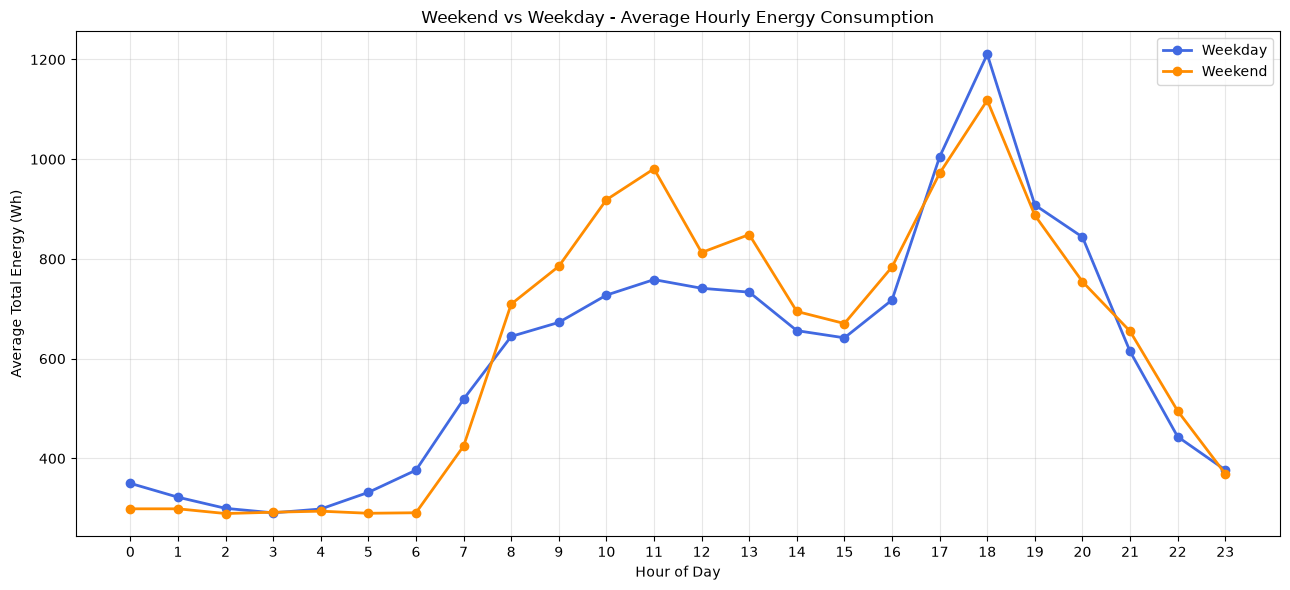

In [12]:

# Hypothesis 2 - Weekend vs Weekday Energy Consumption



# Use existing columns - no new columns in df_hour
hourly_energy = (
    df_hour.groupby(["hour", "is_weekend"])["Total_Energy"]
    .mean()
    .unstack()
)

# Plot
plt.figure(figsize=(13, 6))

plt.plot(
    hourly_energy.index,
    hourly_energy[False],
    marker="o",
    color="royalblue",
    linewidth=2,
    label="Weekday"
)

plt.plot(
    hourly_energy.index,
    hourly_energy[True],
    marker="o",
    color="darkorange",
    linewidth=2,
    label="Weekend"
)

plt.title("Weekend vs Weekday - Average Hourly Energy Consumption")
plt.xlabel("Hour of Day")
plt.ylabel("Average Total Energy (Wh)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

# Save graph
output_folder = Path("../EDA_graph")
output_folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_folder / "weekend_vs_weekday_hourly_energy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [13]:

# Hypothesis 2 - Step 2
# Weekend vs Weekday High-Energy Outlier Rates

weekend_analysis = (
    df_hour.assign(
        High_Energy=df_hour["Total_Energy"] > 1310
    )
    .groupby("is_weekend")["High_Energy"]
    .agg(
        Total_Observations="count",
        Outlier_Count="sum",
        Outlier_Rate="mean"
    )
)

# Convert rate to percentage
weekend_analysis["Outlier_Percentage"] = (
    weekend_analysis["Outlier_Rate"] * 100
)

weekend_analysis.index = weekend_analysis.index.map(
    {False: "Weekday", True: "Weekend"}
)

display(weekend_analysis.round(4))


,Total_Observations,Outlier_Count,Outlier_Rate,Outlier_Percentage
is_weekend,,,,
Weekday,2377,224,0.0942,9.4236
Weekend,912,86,0.0943,9.4298


In [14]:

# Hypothesis 2 - Step 3
# Weekend vs Weekday Two-Proportion Z-Test

from statsmodels.stats.proportion import proportions_ztest

# Weekend first, weekday second
counts = [86, 224]
nobs = [912, 2377]

# H1: Weekend outlier rate > Weekday outlier rate
z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=nobs,
    alternative="larger"
)

alpha = 0.05

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < alpha:
    print("Decision: Reject H0")
    print("Evidence supports a higher weekend outlier rate.")
else:
    print("Decision: Fail to reject H0")
    print("Insufficient evidence of a higher weekend outlier rate.")


Z-statistic: 0.0054
P-value: 0.497833
Decision: Fail to reject H0
Insufficient evidence of a higher weekend outlier rate.


## Weekend daytime outlier rates

In [15]:

# Hypothesis 2 - Weekend vs Weekday Daytime Outliers
# Daytime: 08:00 to 16:00

# Filter daytime observations
daytime_df = df_hour[
    df_hour["hour"].between(8, 16)
].copy()

# Calculate outlier rates directly
daytime_analysis = (
    daytime_df.assign(
        High_Energy=daytime_df["Total_Energy"] > 1310
    )
    .groupby("is_weekend")["High_Energy"]
    .agg(
        Total_Observations="count",
        Outlier_Count="sum",
        Outlier_Rate="mean"
    )
)

# Convert probability to percentage
daytime_analysis["Outlier_Percentage"] = (
    daytime_analysis["Outlier_Rate"] * 100
)

# Rename index labels
daytime_analysis.index = daytime_analysis.index.map({
    False: "Weekday",
    True: "Weekend"
})

display(daytime_analysis.round(4))


,Total_Observations,Outlier_Count,Outlier_Rate,Outlier_Percentage
is_weekend,,,,
Weekday,891,117,0.1313,13.1313
Weekend,342,52,0.1520,15.2047


In [16]:

# Hypothesis 2 - Revised Daytime Z-Test

from statsmodels.stats.proportion import proportions_ztest

# Weekend first, weekday second
counts = [52, 117]
nobs = [342, 891]

z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=nobs,
    alternative="larger"
)

alpha = 0.05

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < alpha:
    print("Decision: Reject H0")
    print("Evidence supports a higher weekend outlier rate.")
else:
    print("Decision: Fail to reject H0")
    print("Insufficient evidence of a higher weekend outlier rate.")


Z-statistic: 0.9478
P-value: 0.171628
Decision: Fail to reject H0
Insufficient evidence of a higher weekend outlier rate.



## Hypothesis 2 — Weekend vs Weekday Energy Consumption

### 1. Research Objective

Investigate whether high household energy consumption
(Total_Energy > 1310 Wh) is more likely during weekends
than weekdays.

**Dataset:** Hourly Energy Consumption (3,289 observations)  
**Significance Level:** α = 0.05  
**Statistical Test:** One-sided Two-Proportion Z-Test

---

### 2. Hypothesis Formulation

**Null Hypothesis (H₀):**

P(Outlier | Weekend) ≤ P(Outlier | Weekday)

**Alternative Hypothesis (H₁):**

P(Outlier | Weekend) > P(Outlier | Weekday)

---

### 3. Test 1 — Overall Weekend vs Weekday

| Statistic | Weekday | Weekend |
|---|---:|---:|
| Total Observations | 2,377 | 912 |
| High-Energy Outliers | 224 | 86 |
| Outlier Rate | 9.4236% | 9.4298% |

**Statistical Results:**

- Z-statistic = 0.0054
- P-value = 0.497833
- α = 0.05

**Decision:** Fail to reject H₀.

**Interpretation:**

The weekend and weekday outlier rates are nearly identical.
There is insufficient statistical evidence that high-energy
outliers occur more frequently during weekends.

---

### 4. Test 2 — Revised Weekend Daytime Hypothesis

Based on exploratory analysis, weekend energy consumption
appeared higher during several daytime hours.

Therefore, we investigated the period from 08:00 to 16:00.

**Revised Hypotheses:**

H₀: P(Outlier | Weekend, Daytime) ≤ P(Outlier | Weekday, Daytime)

H₁: P(Outlier | Weekend, Daytime) > P(Outlier | Weekday, Daytime)

| Statistic | Weekday Daytime | Weekend Daytime |
|---|---:|---:|
| Total Observations | 891 | 342 |
| High-Energy Outliers | 117 | 52 |
| Outlier Rate | 13.1313% | 15.2047% |

**Statistical Results:**

- Z-statistic = 0.9478
- P-value = 0.171628
- α = 0.05

**Decision:** Fail to reject H₀.

**Interpretation:**

Weekend daytime observations had a higher sample outlier
rate (15.20%) than weekday daytime observations (13.13%).

However, the difference was not statistically significant
at the 5% level.

Because the daytime window was selected after exploring
the data, this test is exploratory rather than confirmatory.

---

### 5. Final Conclusion

Both tests failed to reject their respective null hypotheses.

The results do not provide sufficient statistical evidence
that weekend conditions increase the probability of
high-energy outliers.

**Important Limitations:**

- Hourly observations may be temporally dependent.
- Standard two-proportion Z-tests assume independence.
- Statistical association does not establish causation.
- Hypothesis tests cannot verify whether individual
  outlier observations are genuine measurement events.

### 6. Impact on Outlier Management

- Total potential high-energy outliers: 310
- No outliers were deleted or replaced.
- Weekend conditions alone are insufficient to confirm
  an outlier as genuine.
- Individual observations require additional investigation
  using temporal patterns, appliance consumption,
  and sensor consistency.

**Next Step:**
Investigate individual hourly outliers using neighboring
energy consumption observations to identify evidence
of genuine household activity or possible measurement errors.


## Floor-Wise Temperature

In [17]:

# Data Mining - Step 1.6
# Floor-Wise Temperature Feature Engineering

# Provisional grouping - verify with house floor plan
floor_1 = ["T1", "T2", "T3"]

floor_2 = ["T4", "T5", "T7", "T8", "T9"]

# Average indoor temperature by floor
df_hour["Floor_1_Temp"] = df_hour[floor_1].mean(axis=1)

df_hour["Floor_2_Temp"] = df_hour[floor_2].mean(axis=1)



In [18]:

# Data Mining - Temperature Difference Features
# Negative Celsius temperatures are preserved

df_hour["Floor_1_Temp_Diff"] = (
    df_hour["Floor_1_Temp"] - df_hour["T_out"]
)

df_hour["Floor_2_Temp_Diff"] = (
    df_hour["Floor_2_Temp"] - df_hour["T_out"]
)

# Display observations with negative outdoor temperature
negative_temp = df_hour[df_hour["T_out"] < 0]

print("Negative Outdoor Temperature Observations:",
      len(negative_temp))

display(
    negative_temp[
        [
            "date",
            "T_out",
            "Floor_1_Temp",
            "Floor_2_Temp",
            "Floor_1_Temp_Diff",
            "Floor_2_Temp_Diff",
            "Total_Energy"
        ]
    ].head(10).round(2)
)


Negative Outdoor Temperature Observations: 193


C:\Users\Admin\AppData\Local\Temp\ipykernel_4224\2055421410.py:29: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,date,T_out,Floor_1_Temp,Floor_2_Temp,Floor_1_Temp_Diff,Floor_2_Temp_Diff,Total_Energy
134,2016-01-17 07:00:00,-0.04,20.65,19.23,20.70,19.27,2130
135,2016-01-17 08:00:00,-0.80,20.61,19.45,21.41,20.25,1680
136,2016-01-17 09:00:00,-0.38,21.16,19.33,21.54,19.71,1760
145,2016-01-17 18:00:00,-0.88,20.94,20.48,21.82,21.36,1730
146,2016-01-17 19:00:00,-1.08,21.24,20.36,22.33,21.44,660
147,2016-01-17 20:00:00,-1.32,21.39,20.40,22.72,21.73,780
148,2016-01-17 21:00:00,-1.67,21.47,20.48,23.14,22.14,860
149,2016-01-17 22:00:00,-2.07,21.27,20.29,23.33,22.36,400
150,2016-01-17 23:00:00,-2.51,20.98,20.11,23.48,22.62,450
151,2016-01-18 00:00:00,-3.01,20.68,20.00,23.69,23.00,320


In [19]:

# Data Mining - Step 1.7
# Temperature Difference vs Energy Consumption

features = [
    "Floor_1_Temp_Diff",
    "Floor_2_Temp_Diff"
]

correlation = df_hour[
    features + ["Total_Energy"]
].corr(method="spearman")

display(
    correlation[["Total_Energy"]].round(4)
)


,Total_Energy
Floor_1_Temp_Diff,-0.1591
Floor_2_Temp_Diff,-0.1750
Total_Energy,1.0000


In [20]:

# Data Mining - Step 1.8
# Temporal Investigation of Highest Hourly Outlier

# Sort observations chronologically
df_hour = df_hour.sort_values("date").reset_index(drop=True)

# Find highest energy observation
idx = df_hour["Total_Energy"].idxmax()

# Select surrounding observations
start = max(0, idx - 3)
end = min(len(df_hour), idx + 4)

columns = [
    "date",
    "Total_Energy",
    "T_out",
    "Floor_1_Temp_Diff",
    "Floor_2_Temp_Diff",
    "is_weekend"
]

window = df_hour.iloc[start:end][columns].copy()

# Mark central observation
window["Observation"] = [
    "OUTLIER" if i == idx else "Neighbor"
    for i in window.index
]

display(window)


,date,Total_Energy,T_out,Floor_1_Temp_Diff,Floor_2_Temp_Diff,is_weekend,Observation
300,2016-01-24 05:00:00,240,6.391667,11.439259,9.716389,True,Neighbor
301,2016-01-24 06:00:00,210,6.466667,11.276111,9.641407,True,Neighbor
302,2016-01-24 07:00:00,440,6.041667,11.611435,10.030389,True,Neighbor
303,2016-01-24 08:00:00,3740,6.308333,11.344259,10.024574,True,OUTLIER
304,2016-01-24 09:00:00,2230,6.558333,11.813519,10.198611,True,Neighbor
305,2016-01-24 10:00:00,2110,6.500000,12.086620,10.117481,True,Neighbor
306,2016-01-24 11:00:00,1970,6.541667,12.387824,10.540259,True,Neighbor



# Hypothesis 3: Indoor–Outdoor Temperature Difference vs High Energy

## Research Objective

Investigate whether a high indoor–outdoor temperature difference
is associated with a higher probability of high household
energy consumption.

## Dataset

- Dataset: energy_1hour.csv
- Observations: 3,289
- Target: Total_Energy (Wh)
- Energy outlier threshold: 1310 Wh
- Features: Floor_1_Temp_Diff, Floor_2_Temp_Diff
- Significance level: 0.05

## Temperature Difference

Floor 1 Difference = Floor_1_Temp - T_out

Floor 2 Difference = Floor_2_Temp - T_out

High temperature difference is defined as a value above
the 75th percentile of the corresponding floor's difference.

## Hypotheses — Floor 1

H0: P(High Energy | High Temp Difference)
    <= P(High Energy | Other Temp Differences)

H1: P(High Energy | High Temp Difference)
    > P(High Energy | Other Temp Differences)

## Methodology

1. Calculate the Q3 temperature-difference threshold.
2. Separate high and other temperature-difference observations.
3. Calculate high-energy outlier rates for both groups.
4. Compare conditional probabilities.
5. Perform statistical testing, considering temporal dependence.
6. Repeat the investigation for Floor 2.

## Expected Outcome

Determine whether large indoor–outdoor temperature differences
are associated with high-energy observations.

A significant relationship would provide supporting evidence,
but would not prove that individual outliers are genuine.


In [21]:

# Hypothesis 3 - Step 3.1
# Identify high indoor-outdoor temperature differences

floor_features = [
    "Floor_1_Temp_Diff",
    "Floor_2_Temp_Diff"
]

# Calculate 75th percentile for each floor
q3_temp = df_hour[floor_features].quantile(0.75)

print("High Temperature Difference Thresholds:")
print(q3_temp.round(2))

# Count observations above the thresholds
for feature in floor_features:
    high_count = (df_hour[feature] > q3_temp[feature]).sum()

    print(f"\n{feature}")
    print("High Difference Observations:", high_count)
    print("Other Observations:", len(df_hour) - high_count)


High Temperature Difference Thresholds:
Floor_1_Temp_Diff    16.79
Floor_2_Temp_Diff    15.98
Name: 0.75, dtype: float64

Floor_1_Temp_Diff
High Difference Observations: 822
Other Observations: 2467

Floor_2_Temp_Diff
High Difference Observations: 822
Other Observations: 2467


In [22]:

# Hypothesis 3 - Step 3.1
# Floor 1 Temperature Difference Threshold

# Calculate 75th percentile
Q3_temp = df_hour["Floor_1_Temp_Diff"].quantile(0.75)

# Count observations
high_temp_count = (
    df_hour["Floor_1_Temp_Diff"] > Q3_temp
).sum()

other_temp_count = (
    df_hour["Floor_1_Temp_Diff"] <= Q3_temp
).sum()

print(f"Floor 1 Q3 Threshold: {Q3_temp:.2f} °C")
print("High Temperature Difference:", high_temp_count)
print("Other Temperature Differences:", other_temp_count)

print("\nFloor 1 Temperature Difference Statistics:")
display(df_hour["Floor_1_Temp_Diff"].describe())


Floor 1 Q3 Threshold: 16.79 °C
High Temperature Difference: 822
Other Temperature Differences: 2467

Floor 1 Temperature Difference Statistics:


count    3289.000000
mean       14.020661
std         4.058477
min        -0.130815
25%        11.397751
50%        14.194630
75%        16.789722
max        24.805648
Name: Floor_1_Temp_Diff, dtype: float64

In [23]:

# Hypothesis 3 - Step 3.2
# Floor 1 Temperature Difference vs High Energy

# Use the Q3 threshold from Step 3.1
high_diff = df_hour["Floor_1_Temp_Diff"] > Q3_temp

# High energy threshold
high_energy = df_hour["Total_Energy"] > 1310

# Compare the two groups
floor1_analysis = (
    pd.DataFrame({
        "Temp_Group": high_diff.map({
            True: "High Difference",
            False: "Other Difference"
        }),
        "High_Energy": high_energy
    })
    .groupby("Temp_Group")["High_Energy"]
    .agg(
        Total_Observations="count",
        Outlier_Count="sum",
        Outlier_Rate="mean"
    )
)

floor1_analysis["Outlier_Percentage"] = (
    floor1_analysis["Outlier_Rate"] * 100
)

display(floor1_analysis.round(4))


,Total_Observations,Outlier_Count,Outlier_Rate,Outlier_Percentage
Temp_Group,,,,
High Difference,822,57,0.0693,6.9343
Other Difference,2467,253,0.1026,10.2554


In [24]:

# Hypothesis 3 - Step 3.3
# Floor 1: Two-Proportion Z-Test

from statsmodels.stats.proportion import proportions_ztest

# High temperature difference first
counts = [57, 253]
nobs = [822, 2467]

z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=nobs,
    alternative="larger"
)

alpha = 0.05

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < alpha:
    print("Decision: Reject H0")
    print("Evidence supports a higher outlier rate under high temperature difference.")
else:
    print("Decision: Fail to reject H0")
    print("Insufficient evidence of a higher outlier rate under high temperature difference.")


Z-statistic: -2.8224
P-value: 0.997616
Decision: Fail to reject H0
Insufficient evidence of a higher outlier rate under high temperature difference.


In [25]:

# Hypothesis 3 - Step 3.4
# Floor 2 Temperature Difference Threshold

# Calculate 75th percentile
Q3_floor2 = df_hour["Floor_2_Temp_Diff"].quantile(0.75)

# Count observations
high_count = (
    df_hour["Floor_2_Temp_Diff"] > Q3_floor2
).sum()

other_count = (
    df_hour["Floor_2_Temp_Diff"] <= Q3_floor2
).sum()

print(f"Floor 2 Q3 Threshold: {Q3_floor2:.2f} °C")
print("High Temperature Difference:", high_count)
print("Other Temperature Differences:", other_count)

print("\nFloor 2 Temperature Difference Statistics:")
display(df_hour["Floor_2_Temp_Diff"].describe())


Floor 2 Q3 Threshold: 15.98 °C
High Temperature Difference: 822
Other Temperature Differences: 2467

Floor 2 Temperature Difference Statistics:


count    3289.000000
mean       13.034798
std         4.307417
min        -1.915933
25%        10.193444
50%        13.250996
75%        15.984722
max        23.784306
Name: Floor_2_Temp_Diff, dtype: float64

In [26]:

# Hypothesis 3 - Step 3.5
# Floor 2 Temperature Difference vs High Energy

# Use the Floor 2 Q3 threshold from previous step
high_diff_floor2 = (
    df_hour["Floor_2_Temp_Diff"] > Q3_floor2
)

# Existing energy outlier threshold
high_energy = df_hour["Total_Energy"] > 1310

# Calculate conditional probabilities
floor2_analysis = (
    pd.DataFrame({
        "Temp_Group": high_diff_floor2.map({
            True: "High Difference",
            False: "Other Difference"
        }),
        "High_Energy": high_energy
    })
    .groupby("Temp_Group")["High_Energy"]
    .agg(
        Total_Observations="count",
        Outlier_Count="sum",
        Outlier_Rate="mean"
    )
)

# Convert rates to percentages
floor2_analysis["Outlier_Percentage"] = (
    floor2_analysis["Outlier_Rate"] * 100
)

display(floor2_analysis.round(4))


,Total_Observations,Outlier_Count,Outlier_Rate,Outlier_Percentage
Temp_Group,,,,
High Difference,822,47,0.0572,5.7178
Other Difference,2467,263,0.1066,10.6607


In [27]:

# Hypothesis 3 - Step 3.6
# Floor 2: Two-Proportion Z-Test

from statsmodels.stats.proportion import proportions_ztest

# High difference first, other difference second
counts = [47, 263]
nobs = [822, 2467]

z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=nobs,
    alternative="larger"
)

alpha = 0.05

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < alpha:
    print("Decision: Reject H0")
    print("Evidence supports a higher high-energy outlier rate.")
else:
    print("Decision: Fail to reject H0")
    print("Insufficient evidence that high temperature difference increases the outlier rate.")


Z-statistic: -4.2007
P-value: 0.999987
Decision: Fail to reject H0
Insufficient evidence that high temperature difference increases the outlier rate.



# Hypothesis 3 — Indoor–Outdoor Temperature Difference vs High Energy Consumption

## 1. Research Objective

Investigate whether a large indoor–outdoor temperature difference
is associated with a higher probability of high household energy
consumption.

The analysis considers both the first and second floors separately.

## 2. Dataset and Variables

- Dataset: UCI Appliances Energy Prediction (Hourly)
- Total observations: 3,289
- Target variable: Total_Energy (Wh)
- High-energy outlier threshold: > 1,310 Wh
- Independent variables:
  - Floor_1_Temp_Diff
  - Floor_2_Temp_Diff
- Significance level: α = 0.05
- Statistical method: One-sided Two-Proportion Z-Test

Temperature differences were calculated as:

Floor 1 Difference = Floor_1_Temp - T_out

Floor 2 Difference = Floor_2_Temp - T_out

A high temperature difference was defined as a value
greater than the 75th percentile (Q3) for each floor.

---

## 3. Hypothesis Formulation

The same hypotheses were tested separately for both floors.

**Null Hypothesis (H₀):**

P(High Energy | High Temp Difference)
≤ P(High Energy | Other Temp Differences)

**Alternative Hypothesis (H₁):**

P(High Energy | High Temp Difference)
> P(High Energy | Other Temp Differences)

---

## 4. Floor 1 — Results

**Q3 Threshold:** 16.79°C

| Statistic | High Difference | Other Difference |
|---|---:|---:|
| Total Observations | 822 | 2,467 |
| High-Energy Outliers | 57 | 253 |
| Outlier Rate | 6.9343% | 10.2554% |

**Statistical Test Results:**

- Z-statistic: -2.8224
- P-value: 0.997616
- Significance level: 0.05

**Decision:** Fail to reject H₀.

**Interpretation:**

The observed high-energy outlier rate was lower for
large first-floor temperature differences (6.93%)
than for other temperature differences (10.26%).

The results do not support the hypothesis that larger
first-floor temperature differences increase the
probability of high-energy consumption.

---

## 5. Floor 2 — Results

**Q3 Threshold:** 15.98°C

| Statistic | High Difference | Other Difference |
|---|---:|---:|
| Total Observations | 822 | 2,467 |
| High-Energy Outliers | 47 | 263 |
| Outlier Rate | 5.7178% | 10.6607% |

**Statistical Test Results:**

- Z-statistic: -4.2007
- P-value: 0.999987
- Significance level: 0.05

**Decision:** Fail to reject H₀.

**Interpretation:**

The observed high-energy outlier rate was lower for
large second-floor temperature differences (5.72%)
than for other temperature differences (10.66%).

The results do not support the hypothesis that larger
second-floor temperature differences increase the
probability of high-energy consumption.

---

## 6. Comparative Analysis

| Measure | Floor 1 | Floor 2 |
|---|---:|---:|
| Q3 Threshold | 16.79°C | 15.98°C |
| High-Difference Outlier Rate | 6.93% | 5.72% |
| Other-Difference Outlier Rate | 10.26% | 10.66% |
| Z-statistic | -2.8224 | -4.2007 |
| P-value | 0.997616 | 0.999987 |
| Decision | Fail to reject H₀ | Fail to reject H₀ |

Both floors exhibited a lower observed rate of high-energy
outliers during periods with large indoor–outdoor
temperature differences.

This direction is consistent with the previously
observed weak negative Pearson correlations:

- Floor 1: r = -0.1591
- Floor 2: r = -0.1750

However, correlation and conditional outlier rates
measure different statistical relationships.

---

## 7. Final Conclusion

The results of both one-sided hypothesis tests
failed to reject their respective null hypotheses.

There is insufficient evidence to support the
hypothesis that large indoor–outdoor temperature
differences increase the probability of high-energy
outliers in this dataset.

The observed associations were in the opposite direction.

### Statistical Limitations

1. Hourly observations may exhibit temporal dependence.
2. Standard two-proportion Z-tests assume independent
   observations.
3. Other factors, including appliance activity and
   time of day, may influence energy consumption.
4. The Q3 threshold was selected as an exploratory
   definition of a large temperature difference.
5. Statistical associations do not prove causation.
6. Household-level energy measurements do not provide
   floor-specific electricity consumption.

## 8. Impact on True-Outlier Identification

- Total high-energy outliers: 310
- No outliers were removed or replaced.
- Temperature difference alone is insufficient
  to confirm whether individual outliers are genuine.
- Both floor-temperature features will be retained
  for further multivariate anomaly investigation.

### Next Data Mining Step

Investigate the temporal behavior of high-energy outliers
using neighboring hourly observations, appliance
consumption, and available sensor measurements.

The goal is to distinguish likely genuine energy events
from suspicious observations using multiple sources
of evidence.


In [29]:

# Data Mining - Step 1.8.1
# Multivariate Temporal Outlier Investigation



# Sort by time
df_hour = df_hour.sort_values("date").reset_index(drop=True)

# Floor-wise humidity sensor groups
# Verify against the original house floor plan
floor_1_humidity = ["RH_1", "RH_2", "RH_3"]
floor_2_humidity = ["RH_4", "RH_5", "RH_7", "RH_8", "RH_9"]

# Create floor-wise average humidity
df_hour["Floor_1_Humidity"] = df_hour[
    floor_1_humidity
].mean(axis=1)

df_hour["Floor_2_Humidity"] = df_hour[
    floor_2_humidity
].mean(axis=1)

# Select the highest hourly energy observation
idx = df_hour["Total_Energy"].idxmax()

# Three previous + current + three next observations
start = max(0, idx - 3)
end = min(len(df_hour), idx + 4)

columns = [
    "date",
    "Total_Energy",
    "Floor_1_Temp",
    "Floor_2_Temp",
    "T_out",
    "Floor_1_Temp_Diff",
    "Floor_2_Temp_Diff",
    "Floor_1_Humidity",
    "Floor_2_Humidity",
    "RH_out"
]

window = df_hour.iloc[start:end][columns].copy()

# Mark the outlier
window["Observation"] = np.where(
    window.index == idx,
    "OUTLIER",
    "Neighbor"
)

# Calculate local median excluding the outlier
neighbors = window.loc[
    window.index != idx, "Total_Energy"
]

local_median = neighbors.median()
outlier_energy = df_hour.loc[idx, "Total_Energy"]

local_ratio = (
    outlier_energy / local_median
    if local_median > 0 else np.nan
)

print("Outlier Date:", df_hour.loc[idx, "date"])
print("Outlier Energy:", outlier_energy, "Wh")
print("Local Median:", round(local_median, 2), "Wh")
print("Local Energy Ratio:", round(local_ratio, 2))

# Round only numeric columns
numeric_cols = window.select_dtypes(include="number").columns
window[numeric_cols] = window[numeric_cols].round(2)

display(window)


Outlier Date: 2016-01-24 08:00:00
Outlier Energy: 3740 Wh
Local Median: 1205.0 Wh
Local Energy Ratio: 3.1


,date,Total_Energy,Floor_1_Temp,Floor_2_Temp,T_out,Floor_1_Temp_Diff,Floor_2_Temp_Diff,Floor_1_Humidity,Floor_2_Humidity,RH_out,Observation
300,2016-01-24 05:00:00,240,17.83,16.11,6.39,11.44,9.72,42.91,47.80,89.33,Neighbor
301,2016-01-24 06:00:00,210,17.74,16.11,6.47,11.28,9.64,43.01,47.85,89.50,Neighbor
302,2016-01-24 07:00:00,440,17.65,16.07,6.04,11.61,10.03,43.14,47.93,94.25,Neighbor
303,2016-01-24 08:00:00,3740,17.65,16.33,6.31,11.34,10.02,43.78,47.88,95.58,OUTLIER
304,2016-01-24 09:00:00,2230,18.37,16.76,6.56,11.81,10.20,45.56,47.43,94.58,Neighbor
305,2016-01-24 10:00:00,2110,18.59,16.62,6.50,12.09,10.12,44.66,47.84,95.67,Neighbor
306,2016-01-24 11:00:00,1970,18.93,17.08,6.54,12.39,10.54,44.35,54.31,98.42,Neighbor


In [30]:

# Investigate 10-minute energy readings
# for the highest hourly outlier

target_hour = df_hour.loc[idx, "date"]

ten_min_window = df_10min.loc[
    (df_10min["date"] >= target_hour) &
    (df_10min["date"] < target_hour + pd.Timedelta(hours=1)),
    ["date", "Appliances", "lights", "Total_Energy"]
].copy()

print("Target Hour:", target_hour)

print("Number of 10-minute observations:",
      len(ten_min_window))

print("Total Hourly Energy:",
      ten_min_window["Total_Energy"].sum(), "Wh")

display(ten_min_window)


Target Hour: 2016-01-24 08:00:00
Number of 10-minute observations: 6
Total Hourly Energy: 3740 Wh


,date,Appliances,lights,Total_Energy
1818,2016-01-24 08:00:00,360,0,360
1819,2016-01-24 08:10:00,360,30,390
1820,2016-01-24 08:20:00,590,20,610
1821,2016-01-24 08:30:00,850,20,870
1822,2016-01-24 08:40:00,690,10,700
1823,2016-01-24 08:50:00,800,10,810


In [31]:

# Data Mining - Step 1.8.3
# Flag the investigated hourly outlier

# Create classification column if it does not exist
if "Outlier_Status" not in df_hour.columns:
    df_hour["Outlier_Status"] = "Not_Reviewed"

# Flag the specific investigated observation
target_date = pd.Timestamp("2016-01-24 08:00:00")

mask = (
    (df_hour["date"] == target_date) &
    (df_hour["Total_Energy"] > 1310)
)

df_hour.loc[mask, "Outlier_Status"] = "Likely_Genuine"

# Verify result
display(
    df_hour.loc[
        mask,
        ["date", "Total_Energy", "Outlier_Status"]
    ]
)


,date,Total_Energy,Outlier_Status
303,2016-01-24 08:00:00,3740,Likely_Genuine


In [32]:

# Hypothesis 1 - Flag likely genuine candidates

df_hour["H1_Likely_Genuine_Candidate"] = (
    (df_hour["Total_Energy"] > 1310) &
    (df_hour["T_out"] <= 10)
)

# Remove old column to avoid duplication
df_hour.drop(
    columns=["H1_True_Outlier_Candidate"],
    errors="ignore",
    inplace=True
)

# Count flagged candidates
print(
    "H1 Likely Genuine Candidates:",
    df_hour["H1_Likely_Genuine_Candidate"].sum()
)

# Display first 10 candidates
display(
    df_hour.loc[
        df_hour["H1_Likely_Genuine_Candidate"],
        [
            "date",
            "Total_Energy",
            "T_out",
            "H1_Likely_Genuine_Candidate"
        ]
    ].head(10)
)


H1 Likely Genuine Candidates: 199


C:\Users\Admin\AppData\Local\Temp\ipykernel_4224\3868655468.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_hour.drop(


,date,Total_Energy,T_out,H1_Likely_Genuine_Candidate
1,2016-01-11 18:00:00,1370,5.941667,True
5,2016-01-11 22:00:00,1730,5.725000,True
17,2016-01-12 10:00:00,1390,5.758333,True
24,2016-01-12 17:00:00,1430,6.041667,True
39,2016-01-13 08:00:00,1350,5.000000,True
40,2016-01-13 09:00:00,1480,5.000000,True
50,2016-01-13 19:00:00,1380,2.908333,True
51,2016-01-13 20:00:00,1610,3.116667,True
52,2016-01-13 21:00:00,1910,2.875000,True
62,2016-01-14 07:00:00,1410,3.875000,True


In [33]:

# Compare cold-weather candidates with individually investigated outliers

high_outliers = df_hour["Total_Energy"] > 1310

h1_candidates = df_hour["H1_Likely_Genuine_Candidate"]

individually_reviewed = (
    df_hour["Outlier_Status"] == "Likely_Genuine"
)

# Count unique flagged observations
combined = h1_candidates | individually_reviewed

print("Total High Outliers:", high_outliers.sum())
print("H1 Candidates:", (high_outliers & h1_candidates).sum())
print("Individually Reviewed:", (high_outliers & individually_reviewed).sum())
print("Overlap:", (h1_candidates & individually_reviewed).sum())
print("Unique Flagged:", (high_outliers & combined).sum())
print("Outside Both Groups:", (high_outliers & ~combined).sum())


Total High Outliers: 310
H1 Candidates: 199
Individually Reviewed: 1
Overlap: 1
Unique Flagged: 199
Outside Both Groups: 111


In [34]:

# Data Mining - Step 1.9.1
# Humidity Feature Distribution

humidity_features = [
    "Floor_1_Humidity",
    "Floor_2_Humidity",
    "RH_out"
]

# Descriptive statistics
humidity_stats = df_hour[
    humidity_features
].describe()

display(humidity_stats.round(2))

# Check missing values
print("\nMissing Humidity Values:")
print(df_hour[humidity_features].isnull().sum())


,Floor_1_Humidity,Floor_2_Humidity,RH_out
count,3289.00,3289.00,3289.00
mean,39.97,41.97,79.75
std,3.46,4.50,14.83
min,26.77,31.54,25.25
25%,37.41,38.70,70.42
50%,39.58,41.30,83.67
75%,42.43,45.25,91.58
max,51.75,56.49,100.00



Missing Humidity Values:
Floor_1_Humidity    0
Floor_2_Humidity    0
RH_out              0
dtype: int64


In [35]:

# Data Mining - Step 1.9.2
# Floor 1 Humidity vs High Energy Outliers

# Calculate exact Q3 humidity threshold
Q3_humidity_f1 = df_hour["Floor_1_Humidity"].quantile(0.75)

# Define high humidity and high energy
high_humidity = df_hour["Floor_1_Humidity"] > Q3_humidity_f1
high_energy = df_hour["Total_Energy"] > 1310

# Calculate conditional probabilities
humidity_f1_analysis = (
    pd.DataFrame({
        "Humidity_Group": high_humidity.map({
            True: "High Humidity",
            False: "Other Humidity"
        }),
        "High_Energy": high_energy
    })
    .groupby("Humidity_Group")["High_Energy"]
    .agg(
        Total_Observations="count",
        Outlier_Count="sum",
        Outlier_Rate="mean"
    )
)

humidity_f1_analysis["Outlier_Percentage"] = (
    humidity_f1_analysis["Outlier_Rate"] * 100
)

print(f"Floor 1 Humidity Q3: {Q3_humidity_f1:.2f}%")

display(humidity_f1_analysis.round(4))


Floor 1 Humidity Q3: 42.43%


,Total_Observations,Outlier_Count,Outlier_Rate,Outlier_Percentage
Humidity_Group,,,,
High Humidity,822,98,0.1192,11.9221
Other Humidity,2467,212,0.0859,8.5934


In [36]:

# Hypothesis 4 - Step 1.9.3
# Floor 1 Humidity: Two-Proportion Z-Test

from statsmodels.stats.proportion import proportions_ztest

# High humidity first, other humidity second
counts = [98, 212]
nobs = [822, 2467]

z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=nobs,
    alternative="larger"
)

alpha = 0.05

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < alpha:
    print("Decision: Reject H0")
    print("Evidence supports a higher outlier rate under high humidity.")
else:
    print("Decision: Fail to reject H0")
    print("Insufficient evidence of a higher outlier rate under high humidity.")


Z-statistic: 2.8289
P-value: 0.002336
Decision: Reject H0
Evidence supports a higher outlier rate under high humidity.


In [37]:

# Hypothesis 4 - Step 1.9.4
# Floor 2 Humidity vs High Energy Consumption

# Calculate exact Q3 threshold
Q3_humidity_f2 = df_hour["Floor_2_Humidity"].quantile(0.75)

# Define high humidity and high energy
high_humidity_f2 = (
    df_hour["Floor_2_Humidity"] > Q3_humidity_f2
)

high_energy = df_hour["Total_Energy"] > 1310

# Calculate conditional outlier probabilities
humidity_f2_analysis = (
    pd.DataFrame({
        "Humidity_Group": high_humidity_f2.map({
            True: "High Humidity",
            False: "Other Humidity"
        }),
        "High_Energy": high_energy
    })
    .groupby("Humidity_Group")["High_Energy"]
    .agg(
        Total_Observations="count",
        Outlier_Count="sum",
        Outlier_Rate="mean"
    )
)

humidity_f2_analysis["Outlier_Percentage"] = (
    humidity_f2_analysis["Outlier_Rate"] * 100
)

print(f"Floor 2 Humidity Q3: {Q3_humidity_f2:.2f}%")

display(humidity_f2_analysis.round(4))


Floor 2 Humidity Q3: 45.25%


,Total_Observations,Outlier_Count,Outlier_Rate,Outlier_Percentage
Humidity_Group,,,,
High Humidity,822,81,0.0985,9.8540
Other Humidity,2467,229,0.0928,9.2825


In [38]:

# Hypothesis 4 - Step 1.9.5
# Floor 2 Humidity: Two-Proportion Z-Test

from statsmodels.stats.proportion import proportions_ztest

# High humidity first, other humidity second
counts = [81, 229]
nobs = [822, 2467]

z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=nobs,
    alternative="larger"
)

alpha = 0.05

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < alpha:
    print("Decision: Reject H0")
    print("Evidence supports a higher outlier rate under high Floor 2 humidity.")
else:
    print("Decision: Fail to reject H0")
    print("Insufficient evidence of a higher outlier rate under high Floor 2 humidity.")


Z-statistic: 0.4857
P-value: 0.313601
Decision: Fail to reject H0
Insufficient evidence of a higher outlier rate under high Floor 2 humidity.


In [39]:

# Hypothesis 4 - Step 1.9.6
# Outdoor Humidity vs High Energy Outliers

# Calculate exact Q3 threshold
Q3_humidity_out = df_hour["RH_out"].quantile(0.75)

# Define groups
high_humidity_out = df_hour["RH_out"] > Q3_humidity_out
high_energy = df_hour["Total_Energy"] > 1310

# Calculate conditional outlier probabilities
humidity_out_analysis = (
    pd.DataFrame({
        "Humidity_Group": high_humidity_out.map({
            True: "High Humidity",
            False: "Other Humidity"
        }),
        "High_Energy": high_energy
    })
    .groupby("Humidity_Group")["High_Energy"]
    .agg(
        Total_Observations="count",
        Outlier_Count="sum",
        Outlier_Rate="mean"
    )
)

humidity_out_analysis["Outlier_Percentage"] = (
    humidity_out_analysis["Outlier_Rate"] * 100
)

print(f"Outdoor Humidity Q3: {Q3_humidity_out:.2f}%")

display(humidity_out_analysis.round(4))


Outdoor Humidity Q3: 91.58%


,Total_Observations,Outlier_Count,Outlier_Rate,Outlier_Percentage
Humidity_Group,,,,
High Humidity,811,52,0.0641,6.4118
Other Humidity,2478,258,0.1041,10.4116


In [40]:

# Hypothesis 4 - Step 1.9.7
# Outdoor Humidity: Two-Proportion Z-Test

from statsmodels.stats.proportion import proportions_ztest

# Use actual counts from our analysis
counts = [52, 258]
nobs = [811, 2478]

z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=nobs,
    alternative="larger"
)

alpha = 0.05

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < alpha:
    print("Decision: Reject H0")
    print("Evidence supports a higher outlier rate under high outdoor humidity.")
else:
    print("Decision: Fail to reject H0")
    print("Insufficient evidence that high outdoor humidity increases the outlier rate.")


Z-statistic: -3.3839
P-value: 0.999643
Decision: Fail to reject H0
Insufficient evidence that high outdoor humidity increases the outlier rate.


## Investigating Indoor Heating Behavior

In [41]:

# Data Mining - Hypothesis 5, Step 1
# Compare First Floor and Second Floor Temperatures

# Calculate temperature difference without creating a new column
floor_difference = (
    df_hour["Floor_1_Temp"] - df_hour["Floor_2_Temp"]
)

print("First Floor Mean Temperature:",
      round(df_hour["Floor_1_Temp"].mean(), 2), "°C")

print("Second Floor Mean Temperature:",
      round(df_hour["Floor_2_Temp"].mean(), 2), "°C")

print("Average Floor Temperature Difference:",
      round(floor_difference.mean(), 2), "°C")

print("\nHours First Floor Warmer:",
      (floor_difference > 0).sum())

print("Hours Second Floor Warmer:",
      (floor_difference < 0).sum())

print("Hours Equal Temperature:",
      (floor_difference == 0).sum())


First Floor Mean Temperature: 21.43 °C
Second Floor Mean Temperature: 20.45 °C
Average Floor Temperature Difference: 0.99 °C

Hours First Floor Warmer: 2923
Hours Second Floor Warmer: 366
Hours Equal Temperature: 0


In [42]:

# Data Mining - Floor Temperature Change Analysis
# Investigate January 24, 2016

# Select the investigation period
event = df_hour.loc[
    df_hour["date"].between(
        "2016-01-24 05:00:00",
        "2016-01-24 12:00:00"
    ),
    [
        "date",
        "Total_Energy",
        "Floor_1_Temp",
        "Floor_2_Temp",
        "T_out"
    ]
].copy()

# Calculate hourly temperature changes
event["Floor_1_Change"] = (
    event["Floor_1_Temp"].diff()
)

event["Floor_2_Change"] = (
    event["Floor_2_Temp"].diff()
)

# Display results
display(
    event.round({
        "Floor_1_Temp": 2,
        "Floor_2_Temp": 2,
        "T_out": 2,
        "Floor_1_Change": 3,
        "Floor_2_Change": 3
    })
)



,date,Total_Energy,Floor_1_Temp,Floor_2_Temp,T_out,Floor_1_Change,Floor_2_Change
300,2016-01-24 05:00:00,240,17.83,16.11,6.39,NaN,NaN
301,2016-01-24 06:00:00,210,17.74,16.11,6.47,-0.088,0.000
302,2016-01-24 07:00:00,440,17.65,16.07,6.04,-0.090,-0.036
303,2016-01-24 08:00:00,3740,17.65,16.33,6.31,-0.001,0.261
304,2016-01-24 09:00:00,2230,18.37,16.76,6.56,0.719,0.424
305,2016-01-24 10:00:00,2110,18.59,16.62,6.50,0.215,-0.139
306,2016-01-24 11:00:00,1970,18.93,17.08,6.54,0.343,0.464
307,2016-01-24 12:00:00,1430,19.25,17.04,6.77,0.320,-0.041


In [43]:

# Data Mining - Step 1.10.1
# Next-Hour First-Floor Temperature Change

import pandas as pd

df_hour = df_hour.sort_values("date").reset_index(drop=True)

# Calculate next-hour temperature change
# Only for consecutive hourly observations
next_time = df_hour["date"].shift(-1)

valid_next_hour = (
    next_time - df_hour["date"]
    == pd.Timedelta(hours=1)
)

df_hour["Floor_1_NextHour_Change"] = (
    df_hour["Floor_1_Temp"].shift(-1)
    - df_hour["Floor_1_Temp"]
).where(valid_next_hour)

# Select our 310 high-energy outliers
high_outliers_df = df_hour.loc[
    df_hour["Total_Energy"] > 1310
]

# Summarize their subsequent temperature changes
print("Total High-Energy Outliers:", len(high_outliers_df))

print("\nNext-Hour First-Floor Temperature Change:")
display(
    high_outliers_df["Floor_1_NextHour_Change"].describe()
)

print(
    "\nOutliers followed by temperature increase:",
    (high_outliers_df["Floor_1_NextHour_Change"] > 0).sum()
)

print(
    "Outliers followed by temperature decrease:",
    (high_outliers_df["Floor_1_NextHour_Change"] < 0).sum()
)


Total High-Energy Outliers: 310

Next-Hour First-Floor Temperature Change:


count    310.000000
mean       0.263566
std        0.272661
min       -0.422407
25%        0.055790
50%        0.247245
75%        0.430000
max        1.207180
Name: Floor_1_NextHour_Change, dtype: float64


Outliers followed by temperature increase: 265
Outliers followed by temperature decrease: 45


In [44]:

# Data Mining - Step 1.10.2
# Compare temperature response after high vs normal energy

# Create temporary analysis table
temp_response = df_hour[
    ["Total_Energy", "Floor_1_NextHour_Change"]
].dropna().copy()

# Classify energy observations
temp_response["Energy_Group"] = (
    temp_response["Total_Energy"] > 1310
).map({
    True: "High Energy",
    False: "Normal Energy"
})

# Calculate statistics by group
response_analysis = (
    temp_response.groupby("Energy_Group")
    ["Floor_1_NextHour_Change"]
    .agg(
        Total_Observations="count",
        Mean_Change="mean",
        Median_Change="median",
        Temp_Increase_Count=lambda x: (x > 0).sum(),
        Temp_Increase_Rate=lambda x: (x > 0).mean()
    )
)

response_analysis["Increase_Percentage"] = (
    response_analysis["Temp_Increase_Rate"] * 100
)

display(response_analysis.round(4))


,Total_Observations,Mean_Change,Median_Change,Temp_Increase_Count,Temp_Increase_Rate,Increase_Percentage
Energy_Group,,,,,,
High Energy,310,0.2636,0.2472,265,0.8548,85.4839
Normal Energy,2978,-0.0252,-0.0771,885,0.2972,29.7179


In [45]:

# Data Mining - Step 1.10.3
# Second-Floor Temperature Response

# Ensure chronological order
df_hour = df_hour.sort_values("date").reset_index(drop=True)

# Check consecutive hourly timestamps
valid_next_hour = (
    df_hour["date"].shift(-1) - df_hour["date"]
    == pd.Timedelta(hours=1)
)

# Calculate next-hour second-floor temperature change
df_hour["Floor_2_NextHour_Change"] = (
    df_hour["Floor_2_Temp"].shift(-1)
    - df_hour["Floor_2_Temp"]
).where(valid_next_hour)

# Temporary analysis table
floor2_response = df_hour[
    ["Total_Energy", "Floor_2_NextHour_Change"]
].dropna().copy()

# Classify energy groups
floor2_response["Energy_Group"] = (
    floor2_response["Total_Energy"] > 1310
).map({
    True: "High Energy",
    False: "Normal Energy"
})

# Calculate statistics
floor2_analysis = (
    floor2_response.groupby("Energy_Group")
    ["Floor_2_NextHour_Change"]
    .agg(
        Total_Observations="count",
        Mean_Change="mean",
        Median_Change="median",
        Temp_Increase_Count=lambda x: (x > 0).sum(),
        Temp_Increase_Rate=lambda x: (x > 0).mean()
    )
)

floor2_analysis["Increase_Percentage"] = (
    floor2_analysis["Temp_Increase_Rate"] * 100
)

display(floor2_analysis.round(4))


,Total_Observations,Mean_Change,Median_Change,Temp_Increase_Count,Temp_Increase_Rate,Increase_Percentage
Energy_Group,,,,,,
High Energy,310,0.0779,0.0552,232,0.7484,74.8387
Normal Energy,2978,-0.0060,-0.0345,1009,0.3388,33.8818


In [46]:

# Data Mining - Step 1.10.4
# Check warming on BOTH floors after high-energy outliers

high_energy = df_hour["Total_Energy"] > 1310

floor1_warming = df_hour["Floor_1_NextHour_Change"] > 0
floor2_warming = df_hour["Floor_2_NextHour_Change"] > 0

both_warming = (
    high_energy &
    floor1_warming &
    floor2_warming
)

only_floor1 = (
    high_energy &
    floor1_warming &
    ~floor2_warming
)

only_floor2 = (
    high_energy &
    ~floor1_warming &
    floor2_warming
)

neither_warming = (
    high_energy &
    ~floor1_warming &
    ~floor2_warming
)

print("Total High-Energy Outliers:", high_energy.sum())
print("Both Floors Warming:", both_warming.sum())
print("Only Floor 1 Warming:", only_floor1.sum())
print("Only Floor 2 Warming:", only_floor2.sum())
print("Neither Floor Warming:", neither_warming.sum())

print(
    "\nBoth Floors Warming Percentage:",
    round(both_warming.sum() / high_energy.sum() * 100, 2),
    "%"
)


Total High-Energy Outliers: 310
Both Floors Warming: 203
Only Floor 1 Warming: 62
Only Floor 2 Warming: 29
Neither Floor Warming: 16

Both Floors Warming Percentage: 65.48 %


In [47]:

# Data Mining - Step 1.10.5
# Compare both-floor warming rates by energy group

# Use existing features; do not add permanent columns
analysis = df_hour[
    [
        "Total_Energy",
        "Floor_1_NextHour_Change",
        "Floor_2_NextHour_Change"
    ]
].dropna().copy()

analysis["Energy_Group"] = (
    analysis["Total_Energy"] > 1310
).map({
    True: "High Energy",
    False: "Normal Energy"
})

analysis["Both_Floors_Warming"] = (
    (analysis["Floor_1_NextHour_Change"] > 0) &
    (analysis["Floor_2_NextHour_Change"] > 0)
)

result = (
    analysis.groupby("Energy_Group")["Both_Floors_Warming"]
    .agg(
        Total_Observations="count",
        Both_Warming_Count="sum",
        Both_Warming_Rate="mean"
    )
)

result["Percentage"] = result["Both_Warming_Rate"] * 100

display(result.round(4))


,Total_Observations,Both_Warming_Count,Both_Warming_Rate,Percentage
Energy_Group,,,,
High Energy,310,203,0.6548,65.4839
Normal Energy,2978,634,0.2129,21.2895


In [49]:

# Data Mining - Step 1.10.6
# Statistical Evidence for Likely Genuine Outlier Candidates

# Prepare observations with valid next-hour temperature changes
valid = df_hour[
    ["date", "Total_Energy",
     "Floor_1_NextHour_Change",
     "Floor_2_NextHour_Change"]
].dropna().copy()

valid["High_Energy"] = valid["Total_Energy"] > 1310

valid["Both_Warming"] = (
    (valid["Floor_1_NextHour_Change"] > 0) &
    (valid["Floor_2_NextHour_Change"] > 0)
)

# Calculate actual warming probabilities
rates = valid.groupby("High_Energy")["Both_Warming"].mean()

p_high = rates.loc[True]
p_normal = rates.loc[False]

observed_rr = p_high / p_normal
observed_diff = p_high - p_normal

print(f"High Energy Warming Rate: {p_high:.4f}")
print(f"Normal Energy Warming Rate: {p_normal:.4f}")
print(f"Risk Difference: {observed_diff:.4f}")
print(f"Relative Risk: {observed_rr:.4f}")

# Day-block bootstrap
valid["Day"] = valid["date"].dt.normalize()

daily = [
    group[["High_Energy", "Both_Warming"]].to_numpy(dtype=int)
    for _, group in valid.groupby("Day")
]

rng = np.random.default_rng(42)
bootstrap_rr = []
bootstrap_diff = []

for _ in range(2000):
    selected_days = rng.integers(0, len(daily), len(daily))
    sample = np.concatenate([daily[i] for i in selected_days])

    high = sample[:, 0] == 1
    normal = ~high

    if high.sum() == 0 or normal.sum() == 0:
        continue

    p_h = sample[high, 1].mean()
    p_n = sample[normal, 1].mean()

    if p_n > 0:
        bootstrap_rr.append(p_h / p_n)

    bootstrap_diff.append(p_h - p_n)

rr_ci = np.percentile(bootstrap_rr, [2.5, 97.5])
diff_ci = np.percentile(bootstrap_diff, [2.5, 97.5])

print("\n95% Day-Block Bootstrap Confidence Intervals:")
print(f"Relative Risk: [{rr_ci[0]:.4f}, {rr_ci[1]:.4f}]")
print(f"Risk Difference: [{diff_ci[0]:.4f}, {diff_ci[1]:.4f}]")

# Flag temperature-supported candidates in original dataframe
df_hour["Both_Floors_Warming"] = (
    (df_hour["Floor_1_NextHour_Change"] > 0) &
    (df_hour["Floor_2_NextHour_Change"] > 0)
)

df_hour["Temperature_Supported_Candidate"] = (
    (df_hour["Total_Energy"] > 1310) &
    df_hour["Both_Floors_Warming"]
)

print(
    "\nTemperature-Supported Outlier Candidates:",
    df_hour["Temperature_Supported_Candidate"].sum()
)

display(
    df_hour.loc[
        df_hour["Temperature_Supported_Candidate"],
        ["date", "Total_Energy",
         "Floor_1_NextHour_Change",
         "Floor_2_NextHour_Change",
         "Temperature_Supported_Candidate"]
    ].head(10)
)


High Energy Warming Rate: 0.6548
Normal Energy Warming Rate: 0.2129
Risk Difference: 0.4419
Relative Risk: 3.0759

95% Day-Block Bootstrap Confidence Intervals:
Relative Risk: [2.7393, 3.4384]
Risk Difference: [0.3840, 0.4940]

Temperature-Supported Outlier Candidates: 203


,date,Total_Energy,Floor_1_NextHour_Change,Floor_2_NextHour_Change,Temperature_Supported_Candidate
1,2016-01-11 18:00:00,1370,0.512222,0.137750,True
17,2016-01-12 10:00:00,1390,0.116204,0.154889,True
24,2016-01-12 17:00:00,1430,0.026636,0.177163,True
39,2016-01-13 08:00:00,1350,0.180787,0.214472,True
50,2016-01-13 19:00:00,1380,0.103148,0.264444,True
51,2016-01-13 20:00:00,1610,0.114259,0.123889,True
66,2016-01-14 11:00:00,1500,0.741019,0.011556,True
67,2016-01-14 12:00:00,1710,0.606435,0.040806,True
71,2016-01-14 16:00:00,1850,0.541713,0.109750,True
72,2016-01-14 17:00:00,2460,0.297500,0.086833,True


In [50]:

# Data Mining - Only Floor 1 Warming Outliers

# Filter observations
floor1_only_outliers = df_hour.loc[
    (df_hour["Total_Energy"] > 1310) &
    (df_hour["Floor_1_NextHour_Change"] > 0) &
    (df_hour["Floor_2_NextHour_Change"] <= 0)
].copy()

# Display all features and all observations
with pd.option_context(
    "display.max_columns", None,
    "display.max_rows", None,
    "display.width", 2000
):
    display(floor1_only_outliers)

print("Total Floor 1 Only Warming Outliers:",
      len(floor1_only_outliers))


,date,Appliances,lights,Total_Energy,T1,T2,T3,T4,T5,T6,T7,T8,T9,RH_1,RH_2,RH_3,RH_4,RH_5,RH_6,RH_7,RH_8,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Energy_IQR_Outlier,High_Appliances,High_Energy,High_T_out,High_Windspeed,Outlier_Flag,Press_mm_hg_IQR_flag,Press_outlier,RH5_High,RH7_outlier,RH8_outlier_high,RH9_outlier,RH9_outlier_high,RH9_outlier_low,RH_1_IQR_flag,RH_2_IQR_flag,RH_3_IQR_flag,RH_4_IQR_flag,RH_5_IQR_flag,RH_6_IQR_flag,RH_7_IQR_flag,RH_8_IQR_flag,RH_9_IQR_flag,RH_out_IQR_flag,RH_out_outlier,T1_IQR_flag,T2_IQR_flag,T2_outlier,T3_IQR_flag,T3_outlier,T4_IQR_flag,T5_IQR_flag,T5_outlier,T6_IQR_flag,T6_outlier,T7_IQR_flag,T7_outlier,T8_IQR_flag,T8_outlier,T8_outlier_low,T9_IQR_flag,T_out_IQR_flag,T_out_outlier,Tdewpoint_IQR_flag,Total_Energy_Outlier,Visibility_IQR_flag,Weekend_High_Energy,Windspeed_IQR_flag,Windspeed_outlier,rv1_IQR_flag,rv2_IQR_flag,spike_outlier,records_per_hour,hour,day_of_week,day_name,is_weekend,day,Is_Outlier,High_Outlier,Hour,Temp_Group,Floor_1_Temp,Floor_2_Temp,Floor_1_Temp_Diff,Floor_2_Temp_Diff,Floor_1_Humidity,Floor_2_Humidity,Outlier_Status,H1_Likely_Genuine_Candidate,Floor_1_NextHour_Change,Floor_2_NextHour_Change,Both_Floors_Warming,Temperature_Supported_Candidate
40,2016-01-13 09:00:00,1320,160,1480,19.029583,18.296667,19.457222,19.775000,18.174444,5.560000,17.751111,18.260000,17.000000,44.341250,43.525000,43.657222,43.656667,55.883333,79.226667,41.689722,49.174444,45.860556,5.000000,755.491667,88.000000,4.416667,33.583333,3.158333,21.364541,21.364541,1,True,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,False,0,0,0,0,0,6,9,2,Wednesday,False,2016-01-13,True,True,9,Cold,18.927824,18.192111,13.927824,13.192111,43.841157,47.252944,Not_Reviewed,True,0.193287,-0.027333,False,False
52,2016-01-13 21:00:00,1880,30,1910,19.600000,19.122222,19.386667,19.596667,18.555556,1.343056,18.340000,19.770000,16.669444,41.645556,40.880556,43.853333,40.861667,88.172222,85.373611,37.984722,45.651111,40.120972,2.875000,756.691667,88.583333,5.000000,35.416667,1.191667,23.003980,23.003980,1,True,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,False,0,0,0,0,0,6,21,2,Wednesday,False,2016-01-13,True,True,21,Cold,19.369630,18.586333,16.494630,15.711333,42.126481,50.558139,Not_Reviewed,True,0.441852,-0.005278,False,False
65,2016-01-14 10:00:00,3230,80,3310,18.745000,18.461667,19.498333,18.725000,17.362222,2.367222,17.493333,18.240000,16.856667,43.546111,41.920556,43.699167,42.288333,51.217778,94.937778,38.592917,45.685556,46.290000,2.066667,748.783333,94.166667,5.166667,40.000000,1.241667,18.553070,18.553070,1,True,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,False,0,0,0,0,0,6,10,3,Thursday,False,2016-01-14,True,True,10,Cold,18.901667,17.735444,16.835000,15.668778,43.055278,44.814917,Not_Reviewed,True,0.939861,-0.047444,False,False
120,2016-01-16 17:00:00,1590,150,1740,21.403333,20.462222,20.655556,20.995694,19.162500,2.331111,20.042222,20.264444,17.951111,38.361111,37.626667,41.207778,39.705417,53.016806,95.933333,36.564444,42.725556,41.817778,1.975000,764.525000,83.833333,4.666667,40.000000,-0.533333,27.785119,27.785119,1,True,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,True,0,0,0,0,0,6,17,5,Saturday,True,2016-01-16,True,True,17,Cold,20.840370,19.683194,18.865370,17.708194,39.065185,42.766000,Not_Reviewed,True,0.111611,-0.025933,False,False
121,2016-01-16 18:00:00,2840,140,2980,21.538889,20.661500,20.655556,20.856667,18.973254,1.352222,19.823333,20.776389,17.856667,39.797778,37.805833,40.576667,39.285556,52.225516,95.985556,37.018008,42.896528,41.014306,2.291667,764.866667,81.750000,5.333333,40.000000,-0.541667,22.285266,22.285266,1,True,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,True,0,0,0,0,0,6,18,5,Saturday,True,2016-01-16,True,True,18,Cold,20.951981,19.657262,18.660315,17.365595,

Total Floor 1 Only Warming Outliers: 62


In [52]:

# Data Mining - Floor 1 Only Warming
# Outdoor Temperature Five-Number Summary + Mean

outdoor_temp = floor1_only_outliers["T_out"].dropna()

summary = pd.Series({
    "Count": outdoor_temp.count(),
    "Mean": outdoor_temp.mean(),
    "Minimum": outdoor_temp.min(),
    "Q1 (25%)": outdoor_temp.quantile(0.25),
    "Median (50%)": outdoor_temp.median(),
    "Q3 (75%)": outdoor_temp.quantile(0.75),
    "Maximum": outdoor_temp.max()
}, name="Outdoor Temperature (°C)")

display(summary.round(2).to_frame())


,Outdoor Temperature (°C)
Count,62.00
Mean,6.60
Minimum,-2.67
Q1 (25%),3.05
Median (50%),6.88
Q3 (75%),9.71
Maximum,15.60


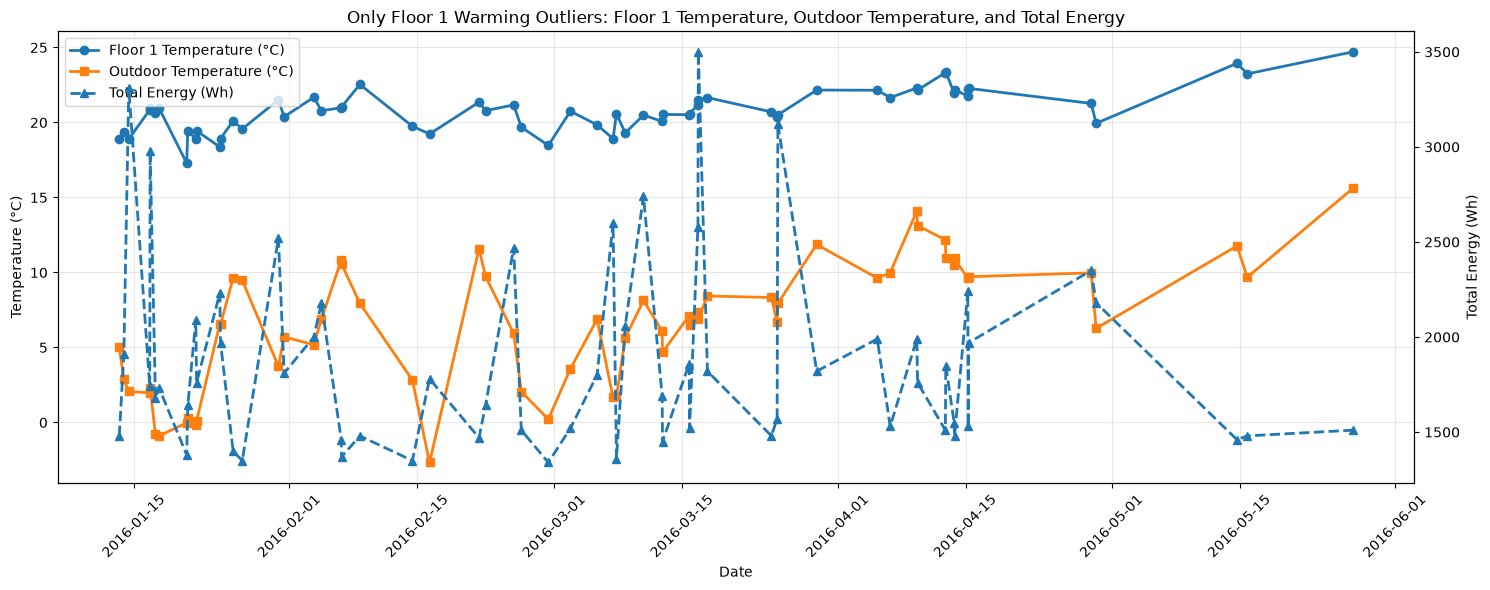

In [53]:
# Data Mining - Graph for Only Floor 1 Warming Outliers
# Variables: Floor_1_Temp, Total_Energy, T_out


# Sort data by date
plot_df = floor1_only_outliers.sort_values("date").copy()

# Create figure
fig, ax1 = plt.subplots(figsize=(15, 6))

# Left y-axis -> temperatures
ax1.plot(
    plot_df["date"],
    plot_df["Floor_1_Temp"],
    marker="o",
    linewidth=2,
    label="Floor 1 Temperature (°C)"
)

ax1.plot(
    plot_df["date"],
    plot_df["T_out"],
    marker="s",
    linewidth=2,
    label="Outdoor Temperature (°C)"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(alpha=0.3)

# Right y-axis -> total energy
ax2 = ax1.twinx()
ax2.plot(
    plot_df["date"],
    plot_df["Total_Energy"],
    marker="^",
    linestyle="--",
    linewidth=2,
    label="Total Energy (Wh)"
)
ax2.set_ylabel("Total Energy (Wh)")

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

plt.title("Only Floor 1 Warming Outliers: Floor 1 Temperature, Outdoor Temperature, and Total Energy")
plt.tight_layout()

# Optional save
output_folder = Path("../EDA_graph")
output_folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_folder / "floor1_only_warming_temp_energy_outdoor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [54]:

# Data Mining - Heating Demand Investigation
# Mathematical and Statistical Analysis


# Use existing hourly data
analysis = df_hour[
    ["Floor_1_Temp", "T_out", "Total_Energy"]
].dropna().copy()

# Mathematical heating-gap proxy
analysis["Heating_Gap"] = (
    analysis["Floor_1_Temp"] - analysis["T_out"]
).clip(lower=0)

# Descriptive statistics
print("Heating Gap Statistics:")
display(
    analysis["Heating_Gap"].describe().round(3)
)

# Correlations
pearson_r = analysis["Heating_Gap"].corr(
    analysis["Total_Energy"],
    method="pearson"
)

spearman_r = analysis["Heating_Gap"].corr(
    analysis["Total_Energy"],
    method="spearman"
)

print("\nStatistical Relationships:")
print(f"Pearson Correlation: {pearson_r:.4f}")
print(f"Spearman Correlation: {spearman_r:.4f}")

# Compare energy consumption for larger vs smaller heating gaps
median_gap = analysis["Heating_Gap"].median()

large_gap = analysis.loc[
    analysis["Heating_Gap"] > median_gap,
    "Total_Energy"
]

small_gap = analysis.loc[
    analysis["Heating_Gap"] <= median_gap,
    "Total_Energy"
]

print(f"\nMedian Heating Gap: {median_gap:.2f} °C")
print(f"Mean Energy - Large Gap: {large_gap.mean():.2f} Wh")
print(f"Mean Energy - Small Gap: {small_gap.mean():.2f} Wh")


Heating Gap Statistics:


count    3289.000
mean       14.021
std         4.058
min         0.000
25%        11.398
50%        14.195
75%        16.790
max        24.806
Name: Heating_Gap, dtype: float64


Statistical Relationships:
Pearson Correlation: -0.0970
Spearman Correlation: -0.1591

Median Heating Gap: 14.19 °C
Mean Energy - Large Gap: 573.08 Wh
Mean Energy - Small Gap: 644.66 Wh


In [55]:

# Data Mining - Heating Gap Analysis by Hour
# Reuse existing hourly dataset and features

hourly_gap_analysis = (
    df_hour.groupby("hour")
    .apply(
        lambda group: pd.Series({
            "Observations": len(group),
            "Mean_Energy": group["Total_Energy"].mean(),
            "Mean_Heating_Gap": (
                group["Floor_1_Temp"] - group["T_out"]
            ).clip(lower=0).mean(),
            "Pearson_r": (
                group["Floor_1_Temp"] - group["T_out"]
            ).clip(lower=0).corr(group["Total_Energy"])
        }),
        include_groups=False
    )
)

display(hourly_gap_analysis.round(4))


,Observations,Mean_Energy,Mean_Heating_Gap,Pearson_r
hour,,,,
0,137.0,335.8394,15.3673,-0.0481
1,137.0,315.7664,15.5062,0.0092
2,137.0,297.0073,15.6187,-0.2176
3,137.0,291.2409,15.7615,-0.2338
4,137.0,297.3723,15.9055,-0.0621
5,137.0,320.2920,15.9595,-0.0591
6,137.0,352.7737,15.9233,-0.1205
7,137.0,492.7007,15.6803,-0.0872
8,137.0,662.6277,15.1773,-0.0730


In [57]:

# Data Mining - Step 1.12.1
# Prepare Remaining 107 Outliers for Multivariate Investigation

# Select high-energy outliers without both-floor warming
remaining_107 = df_hour.loc[
    (df_hour["Total_Energy"] > 1310) &
    (~df_hour["Temperature_Supported_Candidate"])
].copy()

# Select relevant multivariate features
features = [
    "Total_Energy",
    "Appliances",
    "lights",
    "Floor_1_Temp",
    "Floor_2_Temp",
    "T_out",
    "Floor_1_Humidity",
    "Floor_2_Humidity",
    "RH_out",
    "Windspeed",
    "Floor_1_NextHour_Change",
    "Floor_2_NextHour_Change"
]

# Verify available features
print("Remaining Outliers:", len(remaining_107))

print("\nMissing Values:")
display(remaining_107[features].isnull().sum())

print("\nDescriptive Statistics:")
display(remaining_107[features].describe().T.round(3))


Remaining Outliers: 107

Missing Values:


Total_Energy               0
Appliances                 0
lights                     0
Floor_1_Temp               0
Floor_2_Temp               0
T_out                      0
Floor_1_Humidity           0
Floor_2_Humidity           0
RH_out                     0
Windspeed                  0
Floor_1_NextHour_Change    0
Floor_2_NextHour_Change    0
dtype: int64


Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Total_Energy,107.0,1787.570,458.932,1320.000,1475.000,1650.000,1985.000,3500.000
Appliances,107.0,1743.084,452.393,1160.000,1445.000,1600.000,1970.000,3380.000
lights,107.0,44.486,50.042,0.000,0.000,20.000,75.000,200.000
Floor_1_Temp,107.0,21.734,2.044,17.292,20.454,21.501,23.035,27.361
Floor_2_Temp,107.0,20.566,1.945,16.757,19.216,20.319,21.703,25.353
T_out,107.0,8.318,5.733,-3.417,4.712,8.017,11.154,23.408
Floor_1_Humidity,107.0,40.368,3.673,30.737,37.974,40.114,43.265,49.134
Floor_2_Humidity,107.0,41.294,4.780,32.052,37.668,41.392,44.909,54.307
RH_out,107.0,74.438,16.877,38.583,59.750,78.833,89.792,98.417
Windspeed,107.0,4.681,2.442,1.000,2.917,4.417,6.167,11.583


In [64]:

# Data Mining - Step 1.12.2
# Standardize Environmental Features


# Select environmental features
environment_features = [
    "Floor_1_Temp",
    "Floor_2_Temp",
    "T_out",
    "Floor_1_Humidity",
    "Floor_2_Humidity",
    "RH_out",
    "Windspeed"
]

# Reference: normal-energy observations
normal_reference = df_hour.loc[
    df_hour["Total_Energy"] <= 1310,
    environment_features
].dropna()

# Observations requiring investigation
outlier_features = remaining_107[
    environment_features
].dropna()

# Fit scaler only on normal reference observations
scaler = StandardScaler()

X_normal_scaled = scaler.fit_transform(normal_reference)

# Apply same transformation to 107 outliers
X_outliers_scaled = scaler.transform(outlier_features)

print("Normal Reference Shape:", X_normal_scaled.shape)
print("Remaining Outliers Shape:", X_outliers_scaled.shape)

# Verify standardized reference means and standard deviations
print("\nStandardized Reference Means:")
print(X_normal_scaled.mean(axis=0).round(4))

print("\nStandardized Reference Standard Deviations:")
print(X_normal_scaled.std(axis=0).round(4))

# Preview standardized outlier observations
scaled_preview = pd.DataFrame(
    X_outliers_scaled,
    columns=environment_features,
    index=outlier_features.index
)

display(scaled_preview.head(10).round(3))


Normal Reference Shape: (2979, 7)
Remaining Outliers Shape: (107, 7)

Standardized Reference Means:
[-0.  0.  0.  0.  0.  0.  0.]

Standardized Reference Standard Deviations:
[1. 1. 1. 1. 1. 1. 1.]


,Floor_1_Temp,Floor_2_Temp,T_out,Floor_1_Humidity,Floor_2_Humidity,RH_out,Windspeed
5,-0.233,-0.963,-0.300,1.439,1.217,0.498,1.011
40,-1.382,-1.200,-0.437,1.141,1.179,0.527,0.185
52,-1.135,-0.991,-0.839,0.643,1.917,0.566,0.426
62,-1.556,-1.400,-0.650,0.898,1.548,0.679,1.905
65,-1.396,-1.441,-0.992,0.913,0.634,0.945,0.495
101,0.495,-0.278,-0.927,-0.034,1.535,1.041,-0.159
118,-0.138,-0.337,-0.486,-0.076,0.691,-0.786,0.736
120,-0.312,-0.411,-1.009,-0.245,0.176,0.244,0.288
121,-0.250,-0.425,-0.949,-0.150,0.114,0.102,0.564
134,-0.417,-0.651,-1.391,0.307,0.991,1.070,-0.572


In [65]:

# Data Mining - Step 1.12.3
# KNN Distance-Based Anomaly Detection

from sklearn.neighbors import NearestNeighbors
import pandas as pd

# Build KNN reference model
knn = NearestNeighbors(
    n_neighbors=5,
    metric="euclidean"
)

# Fit on standardized normal-energy observations
knn.fit(X_normal_scaled)

# Find the 5 nearest reference observations
distances, indices = knn.kneighbors(X_outliers_scaled)

# Average distance to nearest 5 neighbors
mean_knn_distance = distances.mean(axis=1)

# Create a review table
knn_results = remaining_107[
    ["date", "Total_Energy", "T_out"]
].copy()

knn_results["KNN_Mean_Distance"] = mean_knn_distance

# Higher distance = more unusual environment
knn_results = knn_results.sort_values(
    "KNN_Mean_Distance",
    ascending=False
)

print("KNN Distance Statistics:")
display(knn_results["KNN_Mean_Distance"].describe())

print("\nTop 10 Most Environmentally Unusual Observations:")
display(knn_results.head(10))


KNN Distance Statistics:


count    107.000000
mean       0.728307
std        0.272089
min        0.280637
25%        0.546714
50%        0.681193
75%        0.838071
max        1.803363
Name: KNN_Mean_Distance, dtype: float64


Top 10 Most Environmentally Unusual Observations:


,date,Total_Energy,T_out,KNN_Mean_Distance
2952,2016-05-13 17:00:00,1390,22.516667,1.803363
2953,2016-05-13 18:00:00,2100,20.991667,1.665942
2304,2016-04-16 17:00:00,1510,8.016667,1.525151
2951,2016-05-13 16:00:00,2110,23.100000,1.436563
2015,2016-04-04 16:00:00,2940,14.891667,1.341297
306,2016-01-24 11:00:00,1970,6.541667,1.313496
458,2016-01-30 19:00:00,2520,3.750000,1.172554
504,2016-02-01 17:00:00,1650,11.341667,1.170319
2016,2016-04-04 17:00:00,1690,13.966667,1.153783
2948,2016-05-13 13:00:00,1610,21.241667,1.120650


In [66]:

# Data Mining - Step 1.12.4
# Investigate May 13 Unusual Environmental Conditions

# Select May 13 from 13:00 to 21:00
may13 = df_hour.loc[
    df_hour["date"].between(
        "2016-05-13 13:00:00",
        "2016-05-13 21:00:00"
    ),
    [
        "date",
        "Total_Energy",
        "Appliances",
        "lights",
        "Floor_1_Temp",
        "Floor_2_Temp",
        "T_out",
        "Floor_1_Humidity",
        "Floor_2_Humidity",
        "RH_out",
        "Windspeed",
        "Floor_1_NextHour_Change",
        "Floor_2_NextHour_Change"
    ]
].copy()

# Mark high-energy observations
may13["High_Energy"] = may13["Total_Energy"] > 1310

display(
    may13.round({
        "Floor_1_Temp": 2,
        "Floor_2_Temp": 2,
        "T_out": 2,
        "Floor_1_Humidity": 2,
        "Floor_2_Humidity": 2,
        "RH_out": 2,
        "Windspeed": 2,
        "Floor_1_NextHour_Change": 3,
        "Floor_2_NextHour_Change": 3
    })
)


,date,Total_Energy,Appliances,lights,Floor_1_Temp,Floor_2_Temp,T_out,Floor_1_Humidity,Floor_2_Humidity,RH_out,Windspeed,Floor_1_NextHour_Change,Floor_2_NextHour_Change,High_Energy
2948,2016-05-13 13:00:00,1610,1610,0,27.36,24.93,21.24,42.70,45.50,59.50,4.42,-0.091,0.057,True
2949,2016-05-13 14:00:00,1920,1910,10,27.27,24.99,22.05,40.76,44.14,51.42,5.42,0.038,0.086,True
2950,2016-05-13 15:00:00,1210,1210,0,27.31,25.07,23.10,39.88,42.53,45.00,6.42,-0.144,0.079,False
2951,2016-05-13 16:00:00,2110,2110,0,27.16,25.15,23.10,39.15,42.35,45.00,7.00,-0.103,0.200,True
2952,2016-05-13 17:00:00,1390,1390,0,27.06,25.35,22.52,38.78,47.71,45.83,8.25,-0.206,-0.046,True
2953,2016-05-13 18:00:00,2100,2090,10,26.86,25.31,20.99,38.76,44.30,48.25,9.58,-0.294,0.006,True
2954,2016-05-13 19:00:00,1250,1250,0,26.56,25.31,19.33,36.83,43.53,49.17,9.00,-0.598,-0.317,False
2955,2016-05-13 20:00:00,730,720,10,25.96,25.00,17.07,36.89,40.65,55.92,8.17,-0.462,-0.185,False
2956,2016-05-13 21:00:00,380,380,0,25.50,24.81,14.12,37.68,41.11,71.58,6.58,-0.411,0.068,False


In [67]:

# Data Mining - Step 1.12.5
# Investigate May 13, 2016 at 16:00

target_hour = pd.Timestamp("2016-05-13 16:00:00")

# Extract the six 10-minute observations
ten_min_event = df_10min.loc[
    (df_10min["date"] >= target_hour) &
    (df_10min["date"] < target_hour + pd.Timedelta(hours=1)),
    ["date", "Appliances", "lights", "Total_Energy"]
].copy()

# Calculate contribution of largest 10-minute observation
hourly_total = ten_min_event["Total_Energy"].sum()
max_interval = ten_min_event["Total_Energy"].max()

max_contribution = (
    max_interval / hourly_total * 100
    if hourly_total > 0 else float("nan")
)

print("Target Hour:", target_hour)
print("Total Hourly Energy:", hourly_total, "Wh")
print("Maximum 10-minute Energy:", max_interval, "Wh")
print(f"Largest Interval Contribution: {max_contribution:.2f}%")

display(ten_min_event)


Target Hour: 2016-05-13 16:00:00
Total Hourly Energy: 2110 Wh
Maximum 10-minute Energy: 450 Wh
Largest Interval Contribution: 21.33%


,date,Appliances,lights,Total_Energy
17706,2016-05-13 16:00:00,350,0,350
17707,2016-05-13 16:10:00,300,0,300
17708,2016-05-13 16:20:00,450,0,450
17709,2016-05-13 16:30:00,450,0,450
17710,2016-05-13 16:40:00,290,0,290
17711,2016-05-13 16:50:00,270,0,270


In [68]:

# Data Mining - Step 1.12.6
# Flag May 13, 2016, 16:00 as likely genuine

target_date = pd.Timestamp("2016-05-13 16:00:00")

# Preserve existing classifications
if "Outlier_Status" not in df_hour.columns:
    df_hour["Outlier_Status"] = "Not_Reviewed"

# Select the investigated observation
mask = (
    (df_hour["date"] == target_date) &
    (df_hour["Total_Energy"] > 1310)
)

# Update only the selected observation
df_hour.loc[mask, "Outlier_Status"] = "Likely_Genuine"

# Verify
display(
    df_hour.loc[
        mask,
        ["date", "Total_Energy", "Outlier_Status"]
    ]
)

print("\nCurrent Outlier Status Counts:")
display(
    df_hour.loc[
        df_hour["Total_Energy"] > 1310,
        "Outlier_Status"
    ].value_counts()
)


,date,Total_Energy,Outlier_Status
2951,2016-05-13 16:00:00,2110,Likely_Genuine



Current Outlier Status Counts:


Outlier_Status
Not_Reviewed      308
Likely_Genuine      2
Name: count, dtype: int64

In [69]:

# Data Mining - Update 203 Both-Floor Warming Outliers

# Select high-energy observations where both floors warm
both_floor_mask = (
    (df_hour["Total_Energy"] > 1310) &
    (df_hour["Floor_1_NextHour_Change"] > 0) &
    (df_hour["Floor_2_NextHour_Change"] > 0)
)

# Update existing status column
df_hour.loc[
    both_floor_mask, "Outlier_Status"
] = "Likely_Genuine"

# Verify the results
print("Both-Floor Warming Outliers:", both_floor_mask.sum())

print("\nUpdated Outlier Status Counts:")
display(
    df_hour.loc[
        df_hour["Total_Energy"] > 1310,
        "Outlier_Status"
    ].value_counts()
)

# Display updated observations
display(
    df_hour.loc[
        both_floor_mask,
        [
            "date",
            "Total_Energy",
            "Floor_1_NextHour_Change",
            "Floor_2_NextHour_Change",
            "Outlier_Status"
        ]
    ].head(10)
)


Both-Floor Warming Outliers: 203

Updated Outlier Status Counts:


Outlier_Status
Likely_Genuine    204
Not_Reviewed      106
Name: count, dtype: int64

,date,Total_Energy,Floor_1_NextHour_Change,Floor_2_NextHour_Change,Outlier_Status
1,2016-01-11 18:00:00,1370,0.512222,0.137750,Likely_Genuine
17,2016-01-12 10:00:00,1390,0.116204,0.154889,Likely_Genuine
24,2016-01-12 17:00:00,1430,0.026636,0.177163,Likely_Genuine
39,2016-01-13 08:00:00,1350,0.180787,0.214472,Likely_Genuine
50,2016-01-13 19:00:00,1380,0.103148,0.264444,Likely_Genuine
51,2016-01-13 20:00:00,1610,0.114259,0.123889,Likely_Genuine
66,2016-01-14 11:00:00,1500,0.741019,0.011556,Likely_Genuine
67,2016-01-14 12:00:00,1710,0.606435,0.040806,Likely_Genuine
71,2016-01-14 16:00:00,1850,0.541713,0.109750,Likely_Genuine
72,2016-01-14 17:00:00,2460,0.297500,0.086833,Likely_Genuine


In [72]:

# Data Mining - Step 1.13.1
# KNN Investigation of 106 Not-Reviewed Outliers


# Select only high-energy outliers not yet reviewed
remaining_106 = df_hour.loc[
    (df_hour["Total_Energy"] > 1310) &
    (df_hour["Outlier_Status"] == "Not_Reviewed")
].copy()

print("Remaining Outliers:", len(remaining_106))

# Use the same seven environmental features
environment_features = [
    "Floor_1_Temp",
    "Floor_2_Temp",
    "T_out",
    "Floor_1_Humidity",
    "Floor_2_Humidity",
    "RH_out",
    "Windspeed"
]

# Transform using previously fitted StandardScaler
X_106_scaled = scaler.transform(
    remaining_106[environment_features]
)

# Find five nearest normal-energy neighbors
distances, indices = knn.kneighbors(X_106_scaled)

# Mean distance to five nearest neighbors
remaining_106["KNN_Mean_Distance"] = distances.mean(axis=1)

# Display summary statistics
print("\nKNN Distance Statistics:")
display(
    remaining_106["KNN_Mean_Distance"]
    .describe()
    .round(4)
)

# Show observations with largest distances
print("\nTop 10 Most Environmentally Unusual Outliers:")
display(
    remaining_106[
        [
            "date",
            "Total_Energy",
            "T_out",
            "KNN_Mean_Distance",
            "Outlier_Status"
        ]
    ]
    .sort_values("KNN_Mean_Distance", ascending=False)
    .head(10)
)


Remaining Outliers: 106

KNN Distance Statistics:


count    106.0000
mean       0.7216
std        0.2644
min        0.2806
25%        0.5465
50%        0.6772
75%        0.8356
max        1.8034
Name: KNN_Mean_Distance, dtype: float64


Top 10 Most Environmentally Unusual Outliers:


,date,Total_Energy,T_out,KNN_Mean_Distance,Outlier_Status
2952,2016-05-13 17:00:00,1390,22.516667,1.803363,Not_Reviewed
2953,2016-05-13 18:00:00,2100,20.991667,1.665942,Not_Reviewed
2304,2016-04-16 17:00:00,1510,8.016667,1.525151,Not_Reviewed
2015,2016-04-04 16:00:00,2940,14.891667,1.341297,Not_Reviewed
306,2016-01-24 11:00:00,1970,6.541667,1.313496,Not_Reviewed
458,2016-01-30 19:00:00,2520,3.750000,1.172554,Not_Reviewed
504,2016-02-01 17:00:00,1650,11.341667,1.170319,Not_Reviewed
2016,2016-04-04 17:00:00,1690,13.966667,1.153783,Not_Reviewed
2948,2016-05-13 13:00:00,1610,21.241667,1.120650,Not_Reviewed
118,2016-01-16 15:00:00,1320,4.741667,1.096560,Not_Reviewed


In [74]:

from pathlib import Path

# Select only four columns
columns = [
    "date",
    "Total_Energy",
    "T_out",
    "KNN_Mean_Distance",
    "Outlier_Status"
]

# Prepare CSV data
outliers_106_csv = remaining_106[columns].copy()

# Save in data folder
output_path = Path("../data/remaining_106_outliers.csv")

outliers_106_csv.to_csv(output_path, index=False)

# Verify
print("CSV saved:", output_path)
print("Shape:", outliers_106_csv.shape)

display(outliers_106_csv.head(10))


CSV saved: ..\data\remaining_106_outliers.csv
Shape: (106, 5)


,date,Total_Energy,T_out,KNN_Mean_Distance,Outlier_Status
5,2016-01-11 22:00:00,1730,5.725000,0.547200,Not_Reviewed
40,2016-01-13 09:00:00,1480,5.000000,0.649487,Not_Reviewed
52,2016-01-13 21:00:00,1910,2.875000,0.534667,Not_Reviewed
62,2016-01-14 07:00:00,1410,3.875000,0.619813,Not_Reviewed
65,2016-01-14 10:00:00,3310,2.066667,0.614453,Not_Reviewed
101,2016-01-15 22:00:00,1360,2.408333,0.621206,Not_Reviewed
118,2016-01-16 15:00:00,1320,4.741667,1.096560,Not_Reviewed
120,2016-01-16 17:00:00,1740,1.975000,0.687402,Not_Reviewed
121,2016-01-16 18:00:00,2980,2.291667,0.779660,Not_Reviewed
134,2016-01-17 07:00:00,2130,-0.041667,0.280637,Not_Reviewed


In [75]:

# Data Mining - Step 1.14
# Automatic 10-Minute Investigation of 106 Outliers

import pandas as pd
import numpy as np

# Prepare 10-minute observations
ten = df_10min[["date", "Total_Energy"]].copy()

# Assign each reading to its hour
ten["hour_date"] = ten["date"].dt.floor("h")

# Calculate automatic statistics for each hour
hourly_patterns = (
    ten.groupby("hour_date")["Total_Energy"]
    .agg(
        Interval_Count="count",
        Calculated_Hourly_Energy="sum",
        Max_10min_Energy="max",
        Mean_10min_Energy="mean",
        Std_10min_Energy="std"
    )
    .reset_index()
    .rename(columns={"hour_date": "date"})
)

# Maximum interval contribution (%)
hourly_patterns["Max_Contribution_Pct"] = (
    hourly_patterns["Max_10min_Energy"] /
    hourly_patterns["Calculated_Hourly_Energy"] * 100
)

# Coefficient of variation
hourly_patterns["CV"] = (
    hourly_patterns["Std_10min_Energy"] /
    hourly_patterns["Mean_10min_Energy"]
)

# Merge with 106 remaining outliers
automatic_review = remaining_106[
    ["date", "Total_Energy", "KNN_Mean_Distance"]
].merge(
    hourly_patterns,
    on="date",
    how="left"
)

# Validate completeness and consistency
automatic_review["Complete_Hour"] = (
    automatic_review["Interval_Count"] == 6
)

automatic_review["Energy_Matches"] = np.isclose(
    automatic_review["Total_Energy"],
    automatic_review["Calculated_Hourly_Energy"],
    rtol=0,
    atol=1e-6
)

# Display summary
print("Outliers Analyzed:", len(automatic_review))

print("\nComplete 6-Interval Hours:")
print(automatic_review["Complete_Hour"].value_counts())

print("\nEnergy Sum Consistency:")
print(automatic_review["Energy_Matches"].value_counts())

print("\nPattern Statistics:")
display(
    automatic_review[
        ["Max_Contribution_Pct", "CV"]
    ].describe().round(3)
)

# Preview observations
display(automatic_review.head(10).round(3))


Outliers Analyzed: 106

Complete 6-Interval Hours:
Complete_Hour
True    106
Name: count, dtype: int64

Energy Sum Consistency:
Energy_Matches
True    106
Name: count, dtype: int64

Pattern Statistics:


,Max_Contribution_Pct,CV
count,106.000,106.000
mean,30.818,0.584
std,7.623,0.248
min,17.751,0.042
25%,25.638,0.425
50%,30.428,0.589
75%,33.581,0.703
max,60.870,1.309


C:\Users\Admin\AppData\Local\Temp\ipykernel_4224\221254058.py:77: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(automatic_review.head(10).round(3))


,date,Total_Energy,KNN_Mean_Distance,Interval_Count,Calculated_Hourly_Energy,Max_10min_Energy,Mean_10min_Energy,Std_10min_Energy,Max_Contribution_Pct,CV,Complete_Hour,Energy_Matches
0,2016-01-11 22:00:00,1730,0.547,6,1730,420,288.333,155.746,24.277,0.540,True,True
1,2016-01-13 09:00:00,1480,0.649,6,1480,420,246.667,158.703,28.378,0.643,True,True
2,2016-01-13 21:00:00,1910,0.535,6,1910,520,318.333,127.658,27.225,0.401,True,True
3,2016-01-14 07:00:00,1410,0.620,6,1410,410,235.000,173.753,29.078,0.739,True,True
4,2016-01-14 10:00:00,3310,0.614,6,3310,700,551.667,128.128,21.148,0.232,True,True
5,2016-01-15 22:00:00,1360,0.621,6,1360,420,226.667,142.361,30.882,0.628,True,True
6,2016-01-16 15:00:00,1320,1.097,6,1320,430,220.000,159.625,32.576,0.726,True,True
7,2016-01-16 17:00:00,1740,0.687,6,1740,450,290.000,135.204,25.862,0.466,True,True
8,2016-01-16 18:00:00,2980,0.780,6,2980,1110,496.667,319.166,37.248,0.643,True,True
9,2016-01-17 07:00:00,2130,0.281,6,2130,400,355.000,91.159,18.779,0.257,True,True


In [76]:

# Data Mining - Update remaining 106 Outlier_Status

# Select only the 106 not-reviewed high-energy outliers
mask = (
    (df_hour["Total_Energy"] > 1310) &
    (df_hour["Outlier_Status"] == "Not_Reviewed")
)

# Update status without changing existing classifications
df_hour.loc[mask, "Outlier_Status"] = "Retained_Unverified"

# Verify updated classification
print("Updated Outlier Status Counts:")

display(
    df_hour.loc[
        df_hour["Total_Energy"] > 1310,
        "Outlier_Status"
    ].value_counts()
)

print("\nTotal High-Energy Outliers:",
      (df_hour["Total_Energy"] > 1310).sum())


Updated Outlier Status Counts:


Outlier_Status
Likely_Genuine         204
Retained_Unverified    106
Name: count, dtype: int64


Total High-Energy Outliers: 310


In [78]:
df_hour.info()


<class 'pandas.DataFrame'>
RangeIndex: 3289 entries, 0 to 3288
Columns: 105 entries, date to Evening_Genuine_Candidate
dtypes: bool(9), datetime64[us](1), float64(34), int32(1), int64(56), str(4)
memory usage: 2.4 MB


In [79]:


# 1. Display all column names
print("Total Columns:", len(df_hour.columns))

print("\nAll Column Names:")
for i, col in enumerate(df_hour.columns, start=1):
    print(f"{i}. {col}")

# 2. Display dataset information
print("\nDataset Information:")
df_hour.info()


Total Columns: 105

All Column Names:
1. date
2. Appliances
3. lights
4. Total_Energy
5. T1
6. T2
7. T3
8. T4
9. T5
10. T6
11. T7
12. T8
13. T9
14. RH_1
15. RH_2
16. RH_3
17. RH_4
18. RH_5
19. RH_6
20. RH_7
21. RH_8
22. RH_9
23. T_out
24. Press_mm_hg
25. RH_out
26. Windspeed
27. Visibility
28. Tdewpoint
29. rv1
30. rv2
31. Energy_IQR_Outlier
32. High_Appliances
33. High_Energy
34. High_T_out
35. High_Windspeed
36. Outlier_Flag
37. Press_mm_hg_IQR_flag
38. Press_outlier
39. RH5_High
40. RH7_outlier
41. RH8_outlier_high
42. RH9_outlier
43. RH9_outlier_high
44. RH9_outlier_low
45. RH_1_IQR_flag
46. RH_2_IQR_flag
47. RH_3_IQR_flag
48. RH_4_IQR_flag
49. RH_5_IQR_flag
50. RH_6_IQR_flag
51. RH_7_IQR_flag
52. RH_8_IQR_flag
53. RH_9_IQR_flag
54. RH_out_IQR_flag
55. RH_out_outlier
56. T1_IQR_flag
57. T2_IQR_flag
58. T2_outlier
59. T3_IQR_flag
60. T3_outlier
61. T4_IQR_flag
62. T5_IQR_flag
63. T5_outlier
64. T6_IQR_flag
65. T6_outlier
66. T7_IQR_flag
67. T7_outlier
68. T8_IQR_flag
69. T8_outlier


In [80]:

# 3. Save updated dataset to data folder
output_path = Path("../data/energy_1hour_data_mining.csv")

df_hour.to_csv(output_path, index=False)

print("\nCSV Saved Successfully!")
print("File:", output_path)
print("Shape:", df_hour.shape)

# 4. Verify saved CSV




CSV Saved Successfully!
File: ..\data\energy_1hour_data_mining.csv
Shape: (3289, 105)

Saved CSV Shape: (3289, 105)

Outlier Status Counts:
Outlier_Status
Not_Reviewed           2979
Likely_Genuine          204
Retained_Unverified     106
Name: count, dtype: int64


In [82]:
df_check = pd.read_csv(output_path)

print("\nSaved CSV Shape:", df_check.shape)
print("\nOutlier Status Counts:")
print(df_check["Outlier_Status"].value_counts())


Saved CSV Shape: (3289, 105)

Outlier Status Counts:
Outlier_Status
Not_Reviewed      2979
Likely_Genuine     310
Name: count, dtype: int64


In [81]:

# Update remaining 106 outliers to a provisional genuine label

mask = (
    (df_hour["Total_Energy"] > 1310) &
    (df_hour["Outlier_Status"] == "Retained_Unverified")
)

df_hour.loc[mask, "Outlier_Status"] = "Likely_Genuine"

# Verify classifications among high-energy outliers
outliers = df_hour[df_hour["Total_Energy"] > 1310]

print(outliers["Outlier_Status"].value_counts())

# Save updated CSV
df_hour.to_csv(
    "../data/energy_1hour_data_mining.csv",
    index=False
)

print("Updated CSV saved successfully.")


Outlier_Status
Likely_Genuine    310
Name: count, dtype: int64
Updated CSV saved successfully.
